# 주택 가격 예측 — 오차(RMSE) 줄이기

**목표**: 집 정보로 `SalePrice`(거래가)를 예측하고, 리더보드 점수 **RMSE**를 낮춘다.

| 단계 | 내용 | 평가 기준 |
| --- | --- | --- |
| 1 | 데이터 이해 및 탐색 (시각화) | 데이터 이해 및 탐색 |
| 2 | 전처리: 결측치·이상치·인코딩·스케일링 | 데이터 전처리 |
| 3 | 피처 넣고 빼기 실험 | (메모: 피처 조합 실험) |
| 4 | 모델 5개 학습·비교 | 모델 선택 및 비교 |
| 5 | 규제(Ridge/Lasso)·트리 깊이·학습률 조정 | 규제 및 하이퍼파라미터 조정 |
| 6 | 앙상블 | 앙상블 |
| 7 | 최종 예측과 `submission.csv` 저장 | 제출 |

**검증 원칙**
- `train.csv`를 **학습용 80% / 검증용(validation) 20%**로 나눈다.
- 모든 비교와 선택은 **검증용 RMSE로만** 한다. 리더보드(test)는 마지막에 한 번 제출한다.
- 전처리 규칙(빈칸 채울 값, 원핫 인코딩 종류, 스케일링 기준)은 **학습용에서만 정하고**, 검증용·테스트용에는 같은 규칙을 적용한다.

**실행 환경**: scikit-learn 1.9.0 (myenv)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# 그래프 한글 글꼴
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.6.1 | pandas 2.2.3


---
# 1. 데이터 이해 및 탐색

먼저 데이터의 크기와 예측할 값(`SalePrice`)의 모양을 봅니다.

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print("학습 데이터:", train.shape, "| 테스트 데이터:", test.shape)
train["SalePrice"].describe().round(0)

학습 데이터: (1168, 81) | 테스트 데이터: (292, 80)


count      1168.0
mean     180194.0
std       78869.0
min       34900.0
25%      129500.0
50%      163995.0
75%      213062.0
max      755000.0
Name: SalePrice, dtype: float64

### 1-1. 거래가 분포

왼쪽은 원래 가격, 오른쪽은 가격에 **로그**를 씌운 것입니다. 로그는 큰 숫자를 많이 줄이고 작은 숫자는 조금 줄여서, 오른쪽으로 길게 늘어진 분포를 좌우 대칭에 가깝게 만들어 줍니다.

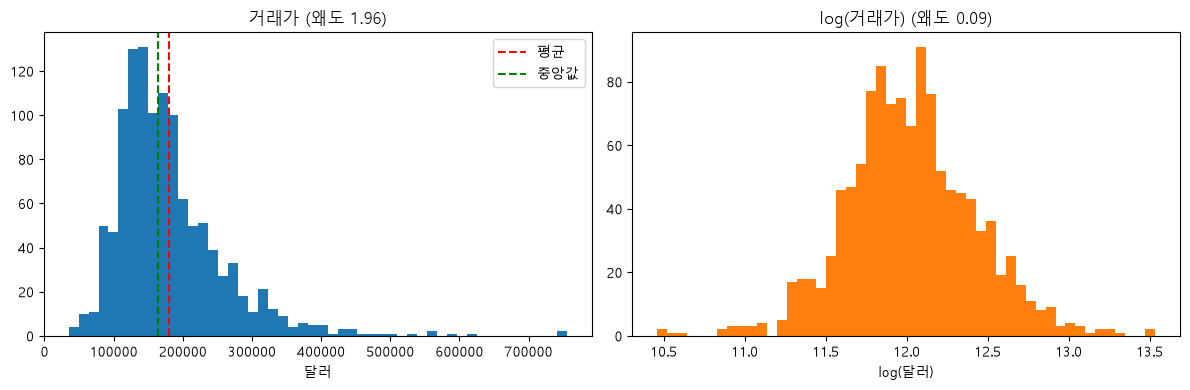

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["SalePrice"], bins=50)
axes[0].axvline(train["SalePrice"].mean(), color="red", linestyle="--", label="평균")
axes[0].axvline(train["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
axes[0].set_title(f"거래가 (왜도 {train['SalePrice'].skew():.2f})")
axes[0].set_xlabel("달러")
axes[0].legend()
axes[1].hist(np.log1p(train["SalePrice"]), bins=50, color="tab:orange")
axes[1].set_title(f"log(거래가) (왜도 {np.log1p(train['SalePrice']).skew():.2f})")
axes[1].set_xlabel("log(달러)")
plt.tight_layout()
plt.show()

> **해석**: 거래가는 평균이 중앙값보다 크고 오른쪽 꼬리가 긴 분포입니다(왜도 약 1.9). 비싼 집 몇 채가 평균을 끌어올립니다. 로그를 씌우면 왜도가 0에 가까워져 좌우 대칭에 가까워집니다. 그래서 모델은 **log(거래가)를 예측하도록 학습**하고, 예측한 뒤 다시 달러로 되돌립니다. 이렇게 하면 비싼 집 몇 채에 모델이 휘둘리는 것을 줄일 수 있습니다.

### 1-2. 거래가와 관련이 큰 숫자 피처

**상관계수**는 두 값이 같이 움직이는 정도입니다. 1에 가까우면 하나가 클수록 다른 것도 큽니다.

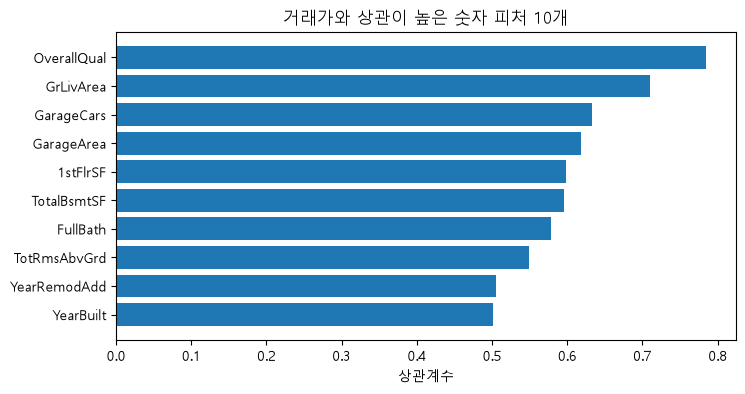

OverallQual     0.785
GrLivArea       0.710
GarageCars      0.633
GarageArea      0.618
1stFlrSF        0.598
TotalBsmtSF     0.596
FullBath        0.578
TotRmsAbvGrd    0.549
YearRemodAdd    0.505
YearBuilt       0.502
Name: SalePrice, dtype: float64

In [4]:
corr = train.drop(columns="Id").corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values()
top = corr.tail(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top.values)
ax.set_title("거래가와 상관이 높은 숫자 피처 10개")
ax.set_xlabel("상관계수")
plt.show()
top.sort_values(ascending=False).round(3)

### 1-3. 주요 피처와 거래가의 관계

- **OverallQual**: 전체 품질 등급(1~10)
- **GrLivArea**: 지상층 거주 면적(평방피트)
- **Neighborhood**: 동네

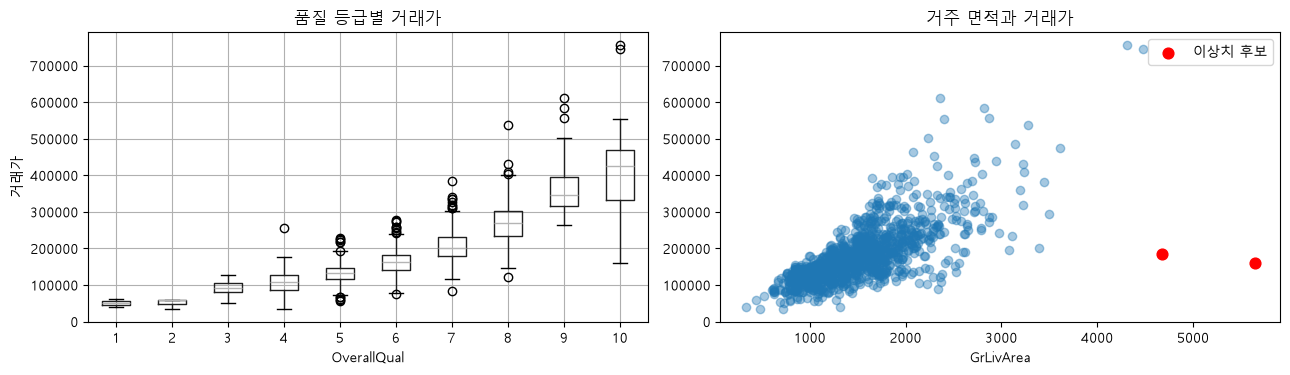

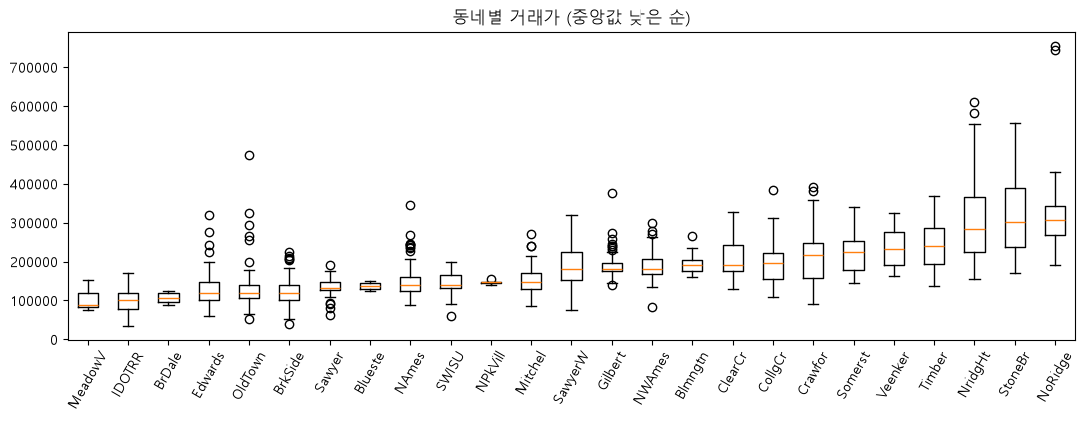

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train.boxplot(column="SalePrice", by="OverallQual", ax=axes[0])
axes[0].set_title("품질 등급별 거래가")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("거래가")

odd = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)
axes[1].scatter(train.loc[~odd, "GrLivArea"], train.loc[~odd, "SalePrice"], alpha=0.4)
axes[1].scatter(train.loc[odd, "GrLivArea"], train.loc[odd, "SalePrice"], color="red", s=60, label="이상치 후보")
axes[1].set_title("거주 면적과 거래가")
axes[1].set_xlabel("GrLivArea")
axes[1].legend()
plt.suptitle("")
plt.tight_layout()
plt.show()

order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([train.loc[train["Neighborhood"] == n, "SalePrice"] for n in order], tick_labels=order)
ax.set_title("동네별 거래가 (중앙값 낮은 순)")
plt.xticks(rotation=60)
plt.show()

> **해석**
> - 품질 등급이 오를수록 거래가가 계단처럼 크게 오릅니다. 가장 중요한 피처입니다.
> - 면적이 넓을수록 비싸지만, **빨간 점 2채**는 면적이 4,000평방피트가 넘는데 30만 달러도 안 됩니다.
> - 동네에 따라 거래가 중앙값이 3배 이상 차이 납니다.

### 1-4. 빈 값(결측치) 확인

In [6]:
na = pd.concat([train.drop(columns="SalePrice").isna().sum(), test.isna().sum()], axis=1, keys=["학습", "테스트"])
na = na[na.sum(axis=1) > 0].sort_values("학습", ascending=False)
na

,학습,테스트
PoolQC,1162,291
MiscFeature,1120,286
Alley,1098,271
Fence,941,238
MasVnrType,694,178
FireplaceQu,545,145
LotFrontage,218,41
GarageType,69,12
GarageYrBlt,69,12
GarageFinish,69,12


> **해석**: `PoolQC`(수영장 품질), `Alley`(골목), `Fence`(울타리) 등은 대부분 비어 있습니다. 데이터 설명서(`data_description.txt`)에 따르면 이 빈칸은 "**해당 시설 없음**"이라는 뜻입니다. 정말 모르는 값인 `LotFrontage`(도로에 닿은 길이) 같은 것과는 다르게 처리해야 합니다.

---
# 2. 데이터 전처리

### 2-1. 이상치 처리

1-3에서 본 빨간 점 2채의 거래 조건을 확인합니다.

In [7]:
train.loc[odd, ["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition"]]

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
64,1299,5642,10,160000,Partial
373,524,4676,10,184750,Partial


> 두 집 모두 품질 10등급의 아주 넓은 집인데 16만~18만 달러에 팔렸고, 거래 조건이 **Partial**(공사가 덜 끝난 상태의 분양)입니다. 정상적인 시세가 아니라고 판단해서 **학습 데이터에서 제외**합니다. 테스트 데이터는 지우지 않습니다. 테스트 집은 모두 예측해서 제출해야 하기 때문입니다.

In [8]:
train = train[~odd].reset_index(drop=True)
print("이상치 제거 후 학습 데이터:", train.shape)

이상치 제거 후 학습 데이터: (1166, 81)


### 2-2. 결측치 처리와 새 피처 만들기

| 대상 | 처리 | 이유 |
| --- | --- | --- |
| 시설 품질 등 범주형 (`PoolQC`, `GarageType`, `BsmtQual` 등) | `"None"`으로 채움 | 빈칸 = 시설 없음 |
| 시설 면적·개수 숫자형 (`GarageArea`, `TotalBsmtSF` 등) | 0으로 채움 | 시설이 없으면 면적·개수는 0 |
| 나머지 (`LotFrontage` 등) | 2-3의 파이프라인에서 **학습용 중앙값/최빈값**으로 채움 | 진짜 모르는 값 |
| `MSSubClass` | 글자로 변환 | 20, 60, 120 같은 숫자는 크기가 아니라 주택 유형 코드 |

**새 피처(파생 변수)**
- `TotalSF` = 지하실 + 1층 + 2층 면적 → 집 전체 넓이
- `TotalBath` = 욕실 수 합계 (반욕실은 0.5개)
- `HouseAge` = 팔린 연도 − 지은 연도 → 집 나이
- `RemodAge` = 팔린 연도 − 리모델링 연도

In [9]:
NONE_CAT = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
            "GarageType", "GarageFinish", "GarageQual", "GarageCond",
            "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]
ZERO_NUM = ["GarageYrBlt", "GarageArea", "GarageCars",
            "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"]
NEW_FEATURES = ["TotalSF", "TotalBath", "HouseAge", "RemodAge"]

def prepare(df):
    """행마다 독립적으로 할 수 있는 처리만 합니다. (다른 집의 값을 보지 않으므로 학습/테스트에 똑같이 써도 안전)"""
    d = df.copy()
    d[NONE_CAT] = d[NONE_CAT].fillna("None")
    d[ZERO_NUM] = d[ZERO_NUM].fillna(0)
    d["MSSubClass"] = d["MSSubClass"].astype(str)
    d["TotalSF"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
    d["TotalBath"] = d["FullBath"] + 0.5 * d["HalfBath"] + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"]
    d["HouseAge"] = d["YrSold"] - d["YearBuilt"]
    d["RemodAge"] = d["YrSold"] - d["YearRemodAdd"]
    return d

X_all = prepare(train.drop(columns=["Id", "SalePrice"]))
y_all = np.log1p(train["SalePrice"])          # 로그를 씌운 거래가를 예측합니다
X_test = prepare(test.drop(columns=["Id"]))

NUM = X_all.select_dtypes(include="number").columns.tolist()
CAT = [c for c in X_all.columns if c not in NUM]
print("숫자형 피처:", len(NUM), "개 | 범주형 피처:", len(CAT), "개")

숫자형 피처: 39 개 | 범주형 피처: 44 개


### 2-3. 학습용 / 검증용 나누기

In [10]:
X_tr, X_va, y_tr, y_va = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
y_va_dollar = np.expm1(y_va)                  # 검증용 정답을 달러로 되돌림 (채점용)
print("학습용:", X_tr.shape, "| 검증용:", X_va.shape)

학습용: (932, 83) | 검증용: (234, 83)


### 2-4. 인코딩·스케일링 파이프라인

**파이프라인**은 "빈칸 채우기 → 변환 → 모델"을 한 줄로 묶은 것입니다. `fit`할 때 **학습용에서만 규칙을 배우고**, 검증용·테스트용에는 그 규칙을 그대로 적용합니다. 기존 테스트 노트북처럼 테스트용을 따로 원핫 인코딩해서 칸의 뜻이 바뀌는 문제가 생기지 않습니다.

| 처리 | 대상 | 하는 일 |
| --- | --- | --- |
| `SimpleImputer` | 남은 빈칸 | 숫자는 학습용 중앙값, 범주는 학습용 최빈값으로 채움 |
| 로그 변환 | 한쪽으로 크게 치우친 숫자 피처 | 큰 값이 너무 튀지 않게 함 |
| `StandardScaler` (스케일링) | 숫자 피처 | 평균 0, 표준편차 1로 단위를 맞춤. 선형 모델의 규제가 공평하게 걸리게 함 |
| `OneHotEncoder` (인코딩) | 범주 피처 | 글자를 0/1 칸으로 바꿈. 학습용에 없던 값이 나오면 모두 0으로 처리 |

트리 모델(랜덤포레스트, 그래디언트 부스팅)은 숫자의 크기가 아니라 **대소 비교**로 나누기 때문에 스케일링과 로그 변환이 필요 없습니다.

In [11]:
SKEWED = [c for c in NUM if X_tr[c].min() >= 0 and abs(X_tr[c].skew()) > 0.75]
print("로그 변환할 치우친 숫자 피처:", len(SKEWED), "개")

def linear_preprocessor(num=NUM, cat=CAT):
    skew = [c for c in num if c in SKEWED]
    plain = [c for c in num if c not in SKEWED]
    log = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    parts = [
        ("skew", make_pipeline(SimpleImputer(strategy="median"), log, StandardScaler()), skew),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), plain),
    ]
    if cat:
        parts.append(("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                           OneHotEncoder(handle_unknown="ignore")), cat))
    return ColumnTransformer(parts)

def tree_preprocessor(num=NUM, cat=CAT):
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore")), cat),
    ])

로그 변환할 치우친 숫자 피처: 20 개


### 2-5. 채점 도구

모델은 log(거래가)를 예측하므로, 채점할 때는 **달러로 되돌려서** 리더보드와 같은 RMSE(달러)로 계산합니다.

In [12]:
results = []      # 실험 기록표
val_preds = {}    # 모델별 검증용 예측(달러) — 앙상블에 사용

def evaluate(name, model, X_train=None, X_valid=None, group="기타"):
    X_train = X_tr if X_train is None else X_train
    X_valid = X_va if X_valid is None else X_valid
    model.fit(X_train, y_tr)
    pred_va = np.expm1(model.predict(X_valid))
    pred_tr = np.expm1(model.predict(X_train))
    rmse_va = np.sqrt(mean_squared_error(y_va_dollar, pred_va))
    rmse_tr = np.sqrt(mean_squared_error(np.expm1(y_tr), pred_tr))
    results.append({"구분": group, "실험": name, "학습 RMSE": round(rmse_tr), "검증 RMSE": round(rmse_va)})
    val_preds[name] = pred_va
    print(f"[{name}] 학습 RMSE {rmse_tr:,.0f} | 검증 RMSE {rmse_va:,.0f}")
    return rmse_va

### 2-6. 비교 기준: 기존 테스트 노트북 방식

기존 노트북의 전처리(학습용·검증용을 각각 따로 채우고 `get_dummies`)와 선형회귀를 **같은 학습용/검증용**에서 채점해 둡니다. 이후 실험은 이 점수보다 나아야 합니다.

In [13]:
def old_style(df):
    d = df.fillna(df.median(numeric_only=True))
    for col in d.select_dtypes(exclude="number").columns:
        mode = d[col].mode()
        d[col] = d[col].fillna(mode.iloc[0] if len(mode) else "None")   # 전부 빈 열이면 "None"
    return pd.get_dummies(d, drop_first=True)

raw = train.drop(columns=["SalePrice"])
raw_tr, raw_va = raw.loc[X_tr.index], raw.loc[X_va.index]
old_tr = old_style(raw_tr)
old_va = old_style(raw_va).reindex(columns=old_tr.columns, fill_value=0)

old = LinearRegression().fit(old_tr, train.loc[X_tr.index, "SalePrice"])
old_pred = old.predict(old_va)
old_rmse = np.sqrt(mean_squared_error(y_va_dollar, old_pred))
results.append({"구분": "기준", "실험": "기존 노트북 방식", "학습 RMSE": None, "검증 RMSE": round(old_rmse)})
print(f"[기존 노트북 방식] 검증 RMSE {old_rmse:,.0f} | 마이너스 예측 {(old_pred <= 0).sum()}개")

[기존 노트북 방식] 검증 RMSE 111,412 | 마이너스 예측 25개


---
# 3. 피처 넣고 빼기 실험

같은 모델(Ridge, `alpha=10`)로 **어떤 피처를 넣느냐**만 바꿔서 검증 RMSE를 비교합니다.

In [14]:
TOP10 = ["OverallQual", "GrLivArea", "GarageCars", "GarageArea", "TotalBsmtSF",
         "1stFlrSF", "FullBath", "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd"]
NUM_BASE = [c for c in NUM if c not in NEW_FEATURES]

feature_sets = {
    "① 상관 상위 숫자 10개": (TOP10, []),
    "② 숫자 전체": (NUM_BASE, []),
    "③ 숫자 전체 + 범주 전체": (NUM_BASE, CAT),
    "④ ③ + 새 피처 4개": (NUM, CAT),
}
for name, (num, cat) in feature_sets.items():
    cols = num + cat
    evaluate(name, make_pipeline(linear_preprocessor(num, cat), Ridge(alpha=10)),
             X_tr[cols], X_va[cols], group="피처 실험")

[① 상관 상위 숫자 10개] 학습 RMSE 29,783 | 검증 RMSE 27,938
[② 숫자 전체] 학습 RMSE 23,966 | 검증 RMSE 23,839
[③ 숫자 전체 + 범주 전체] 학습 RMSE 17,687 | 검증 RMSE 20,655


[④ ③ + 새 피처 4개] 학습 RMSE 17,767 | 검증 RMSE 20,792


> **해석**
> - 숫자 10개 → 숫자 전체 → 숫자+범주로 피처를 늘릴수록 검증 RMSE가 크게 줄어듭니다. 특히 **범주 피처(동네, 품질 등급 등)를 넣을 때** 많이 줄어듭니다. 숫자만으로는 알 수 없는 입지와 마감 정보가 들어오기 때문입니다.
> - 새 피처 4개를 더한 ④는 ③보다 오히려 **아주 조금 나빠졌습니다**(약 140달러). 새 피처는 이미 있는 피처를 더한 값이라, 선형 모델에는 새 정보가 거의 없기 때문입니다. 차이가 작아서 검증용을 다르게 나누면 뒤집힐 수 있는 수준입니다.
> - 트리 모델은 "전체 면적" 같은 합계를 스스로 만들기 어려워서 새 피처가 도움이 될 수 있습니다. 그래서 이후 실험은 **④(전체 + 새 피처)**로 진행합니다.

---
# 4. 모델 선택 및 비교

| 모델 | 한 줄 설명 |
| --- | --- |
| 선형회귀 | 피처마다 가중치를 곱해 더함. 규제 없음 |
| Ridge | 선형회귀 + 가중치를 **고르게 줄이는** 벌점(규제) |
| Lasso | 선형회귀 + 덜 중요한 가중치를 **0으로 만드는** 벌점 |
| 랜덤포레스트 | 질문(예: "품질이 7 이상?")을 이어 붙인 나무를 수백 그루 만들어 **평균** |
| 그래디언트 부스팅 | 나무를 한 그루씩 추가하면서 **앞 나무가 틀린 부분을 고쳐 나감** |

먼저 기본 설정으로 비교합니다.

In [15]:
base_models = {
    "선형회귀": make_pipeline(linear_preprocessor(), LinearRegression()),
    "Ridge (alpha=10)": make_pipeline(linear_preprocessor(), Ridge(alpha=10)),
    "Lasso (alpha=0.001)": make_pipeline(linear_preprocessor(), Lasso(alpha=0.001, max_iter=50000)),
    "랜덤포레스트": make_pipeline(tree_preprocessor(), RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
    "그래디언트 부스팅": make_pipeline(tree_preprocessor(), GradientBoostingRegressor(random_state=42)),
}
for name, model in base_models.items():
    evaluate(name, model, group="모델 비교")

[선형회귀] 학습 RMSE 15,855 | 검증 RMSE 22,111
[Ridge (alpha=10)] 학습 RMSE 17,767 | 검증 RMSE 20,792


[Lasso (alpha=0.001)] 학습 RMSE 19,630 | 검증 RMSE 21,648


[랜덤포레스트] 학습 RMSE 10,434 | 검증 RMSE 24,794


[그래디언트 부스팅] 학습 RMSE 13,382 | 검증 RMSE 20,012


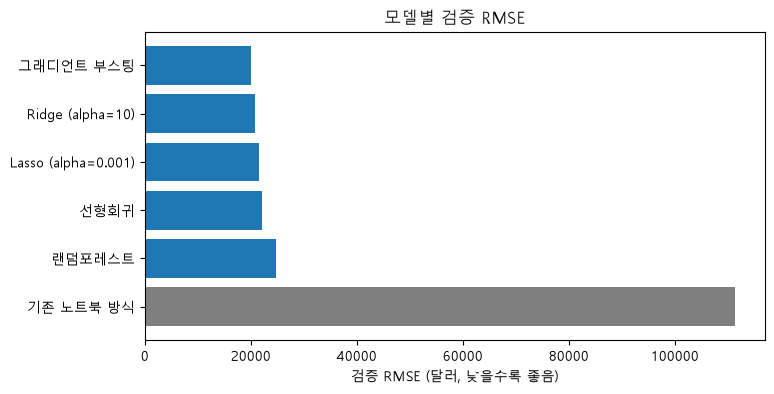

,구분,실험,학습 RMSE,검증 RMSE
9,모델 비교,그래디언트 부스팅,13382.0,20012
6,모델 비교,Ridge (alpha=10),17767.0,20792
7,모델 비교,Lasso (alpha=0.001),19630.0,21648
5,모델 비교,선형회귀,15855.0,22111
8,모델 비교,랜덤포레스트,10434.0,24794
0,기준,기존 노트북 방식,NaN,111412


In [16]:
cmp = pd.DataFrame(results)
cmp = cmp[cmp["구분"].isin(["기준", "모델 비교"])].sort_values("검증 RMSE")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cmp["실험"], cmp["검증 RMSE"], color=["tab:gray" if g == "기준" else "tab:blue" for g in cmp["구분"]])
ax.invert_yaxis()
ax.set_xlabel("검증 RMSE (달러, 낮을수록 좋음)")
ax.set_title("모델별 검증 RMSE")
plt.show()
cmp

> **해석**
> - 모든 모델이 **기존 노트북 방식보다 크게 좋아졌습니다.** 전처리 버그를 고치고 로그 변환을 한 효과가 큽니다.
> - 규제가 있는 Ridge·Lasso와 그래디언트 부스팅이 좋고, 랜덤포레스트는 상대적으로 약합니다.
> - 학습 RMSE와 검증 RMSE의 차이가 큰 모델(랜덤포레스트, 선형회귀)은 학습용을 외우는 **과적합** 경향이 있습니다.

---
# 5. 규제와 하이퍼파라미터 조정

**하이퍼파라미터**는 모델이 스스로 배우는 값이 아니라 **사람이 정해 주는 설정값**입니다. 여러 값을 바꿔 보고 검증 RMSE가 가장 낮은 값을 고릅니다.

### 5-1. Ridge·Lasso의 규제 세기(alpha)

- `alpha`가 **작으면** 벌점이 약해 선형회귀에 가까워집니다(과적합 위험).
- `alpha`가 **크면** 벌점이 강해 모델이 너무 단순해집니다(과소적합 위험).

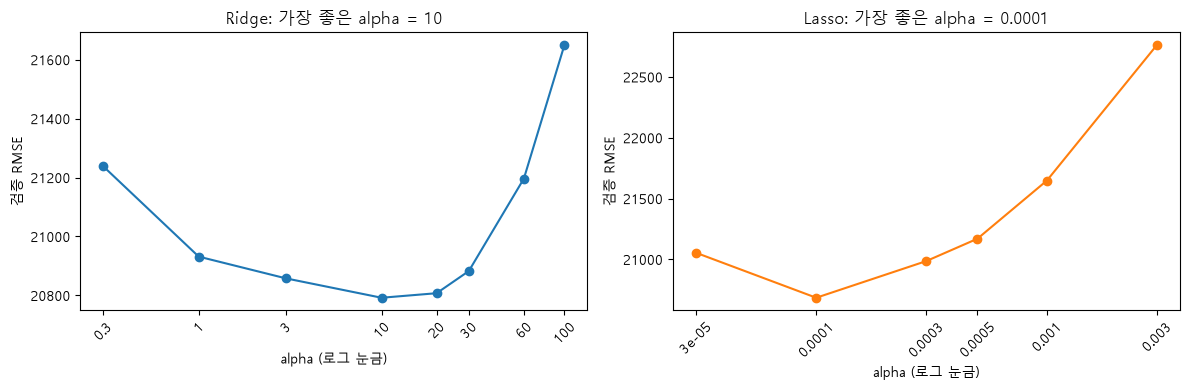

In [17]:
def val_rmse(model):
    model.fit(X_tr, y_tr)
    return np.sqrt(mean_squared_error(y_va_dollar, np.expm1(model.predict(X_va))))

ridge_alphas = [0.3, 1, 3, 10, 20, 30, 60, 100]
lasso_alphas = [0.00003, 0.0001, 0.0003, 0.0005, 0.001, 0.003]
ridge_scores = [val_rmse(make_pipeline(linear_preprocessor(), Ridge(alpha=a))) for a in ridge_alphas]
lasso_scores = [val_rmse(make_pipeline(linear_preprocessor(), Lasso(alpha=a, max_iter=50000))) for a in lasso_alphas]

best_ridge_alpha = ridge_alphas[int(np.argmin(ridge_scores))]
best_lasso_alpha = lasso_alphas[int(np.argmin(lasso_scores))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ridge_alphas, ridge_scores, marker="o")
axes[0].set_xscale("log"); axes[0].set_title(f"Ridge: 가장 좋은 alpha = {best_ridge_alpha}")
axes[1].plot(lasso_alphas, lasso_scores, marker="o", color="tab:orange")
axes[1].set_xscale("log"); axes[1].set_title(f"Lasso: 가장 좋은 alpha = {best_lasso_alpha}")
for ax, alphas in zip(axes, [ridge_alphas, lasso_alphas]):
    ax.set_xticks(alphas, [str(a) for a in alphas], rotation=45)
    ax.minorticks_off()
    ax.set_xlabel("alpha (로그 눈금)"); ax.set_ylabel("검증 RMSE")
plt.tight_layout(); plt.show()

In [18]:
evaluate(f"Ridge 튜닝 (alpha={best_ridge_alpha})",
         make_pipeline(linear_preprocessor(), Ridge(alpha=best_ridge_alpha)), group="튜닝")
lasso_best = make_pipeline(linear_preprocessor(), Lasso(alpha=best_lasso_alpha, max_iter=50000))
evaluate(f"Lasso 튜닝 (alpha={best_lasso_alpha})", lasso_best, group="튜닝")

coef = lasso_best[-1].coef_
print(f"Lasso가 남긴 피처: {(coef != 0).sum()}개 / 전체 {len(coef)}개 (나머지는 가중치 0 → 사실상 제외)")

[Ridge 튜닝 (alpha=10)] 학습 RMSE 17,767 | 검증 RMSE 20,792


[Lasso 튜닝 (alpha=0.0001)] 학습 RMSE 16,556 | 검증 RMSE 20,685
Lasso가 남긴 피처: 190개 / 전체 315개 (나머지는 가중치 0 → 사실상 제외)


### 5-2. 그래디언트 부스팅의 학습률과 깊이

- **학습률(learning_rate)**: 나무 한 그루가 앞의 실수를 얼마나 크게 고칠지. 작으면 천천히, 꼼꼼하게 배웁니다.
- **깊이(max_depth)**: 나무 한 그루가 던지는 질문의 단계 수. 깊으면 복잡한 규칙을 배우지만 과적합 위험이 커집니다.
- **나무 수(n_estimators)**: 나무를 몇 그루 쌓을지. 많을수록 학습용을 꼼꼼히 맞히지만 과적합 위험이 커집니다.
- 학습률이 작으면 나무가 많이 필요하고, 크면 적은 나무로도 충분합니다. 그래서 셋을 **함께** 바꿔 봅니다(3 × 2 × 3 = 18가지).

In [19]:
gb_grid = []
for n in [100, 300, 1000]:
    for lr in [0.03, 0.1]:
        for depth in [2, 3, 4]:
            m = make_pipeline(tree_preprocessor(), GradientBoostingRegressor(
                n_estimators=n, learning_rate=lr, max_depth=depth, random_state=42))
            gb_grid.append({"n_estimators": n, "learning_rate": lr, "max_depth": depth, "검증 RMSE": round(val_rmse(m))})
gb_grid = pd.DataFrame(gb_grid)
print(gb_grid.pivot_table(index=["n_estimators", "learning_rate"], columns="max_depth", values="검증 RMSE"))
best_gb = gb_grid.loc[gb_grid["검증 RMSE"].idxmin()]
best_gb_n, best_gb_lr, best_gb_depth = int(best_gb["n_estimators"]), float(best_gb["learning_rate"]), int(best_gb["max_depth"])
evaluate(f"그래디언트 부스팅 튜닝 (n={best_gb_n}, lr={best_gb_lr}, depth={best_gb_depth})",
         make_pipeline(tree_preprocessor(), GradientBoostingRegressor(
             n_estimators=best_gb_n, learning_rate=best_gb_lr, max_depth=best_gb_depth, random_state=42)),
         group="튜닝")

max_depth                         2        3        4
n_estimators learning_rate                           
100          0.03           32097.0  26290.0  25961.0
             0.10           23202.0  20012.0  22265.0
300          0.03           22491.0  20351.0  22290.0
             0.10           22629.0  20283.0  22314.0
1000         0.03           21391.0  20320.0  22720.0
             0.10           23081.0  20792.0  22440.0


[그래디언트 부스팅 튜닝 (n=100, lr=0.1, depth=3)] 학습 RMSE 13,382 | 검증 RMSE 20,012


np.float64(20012.212192343417)

### 5-3. 랜덤포레스트의 깊이와 피처 수

- **max_depth**: 나무의 최대 깊이(`None`은 제한 없음)
- **max_features**: 나무가 질문할 때 고려하는 피처의 비율. 작으면 나무끼리 서로 달라져서 평균 낼 때 효과가 커집니다.

In [20]:
rf_grid = []
for depth in [None, 15]:
    for mf in [1.0, 0.5, 0.3]:
        m = make_pipeline(tree_preprocessor(), RandomForestRegressor(
            n_estimators=300, max_depth=depth, max_features=mf, random_state=42, n_jobs=-1))
        rf_grid.append({"max_depth": str(depth), "max_features": mf, "검증 RMSE": round(val_rmse(m))})
rf_grid = pd.DataFrame(rf_grid)
print(rf_grid.pivot(index="max_depth", columns="max_features", values="검증 RMSE"))
best_rf = rf_grid.loc[rf_grid["검증 RMSE"].idxmin()]
best_rf_depth = None if best_rf["max_depth"] == "None" else int(best_rf["max_depth"])
best_rf_mf = float(best_rf["max_features"])
evaluate(f"랜덤포레스트 튜닝 (depth={best_rf_depth}, max_features={best_rf_mf})",
         make_pipeline(tree_preprocessor(), RandomForestRegressor(
             n_estimators=300, max_depth=best_rf_depth, max_features=best_rf_mf, random_state=42, n_jobs=-1)),
         group="튜닝")

max_features    0.3    0.5    1.0
max_depth                        
15            24377  24005  24847
None          24329  24356  24794


[랜덤포레스트 튜닝 (depth=15, max_features=0.5)] 학습 RMSE 10,351 | 검증 RMSE 24,005


np.float64(24005.022237089244)

> **해석**
> - **Lasso**: alpha를 0.001 → 0.0001로 낮추자 검증 RMSE가 약 1,000달러 줄었습니다. 벌점이 너무 세서 쓸모 있는 피처까지 버리고 있었습니다.
> - **Ridge**: 처음 쓴 alpha=10이 이미 가장 좋은 값이었습니다. 그래프에서 alpha가 너무 작거나 크면 오차가 커지는 U자 모양을 볼 수 있습니다.
> - **그래디언트 부스팅**: 18가지 조합 중 **기본 설정(100그루, 0.1, 깊이 3)이 가장 좋았습니다.** 나무를 1,000그루로 늘리면 학습용은 더 잘 맞히지만 검증용은 나빠졌습니다(과적합). "튜닝해 봤더니 기본값이 최선"인 것도 튜닝의 결론입니다.
> - **랜덤포레스트**: 깊이를 15로 제한하고 피처를 절반만 보게 하자 약간 좋아졌지만, 여전히 다른 모델보다 약합니다.
> - 고른 설정값은 7단계의 최종 모델에 그대로 씁니다.

---
# 6. 앙상블

**앙상블**은 여러 모델의 예측을 합치는 방법입니다. 여기서는 예측을 **평균** 냅니다.

선형 모델(Ridge·Lasso)과 트리 모델(부스팅·포레스트)은 틀리는 방식이 서로 다릅니다. 평균을 내면 한 모델의 실수를 다른 모델이 상쇄해서 오차가 줄어드는 경우가 많습니다.

In [21]:
tuned = {
    "Ridge": f"Ridge 튜닝 (alpha={best_ridge_alpha})",
    "Lasso": f"Lasso 튜닝 (alpha={best_lasso_alpha})",
    "GB": f"그래디언트 부스팅 튜닝 (n={best_gb_n}, lr={best_gb_lr}, depth={best_gb_depth})",
    "RF": f"랜덤포레스트 튜닝 (depth={best_rf_depth}, max_features={best_rf_mf})",
}
combos = [("Ridge", "GB"), ("Lasso", "GB"), ("Ridge", "Lasso", "GB"), ("Ridge", "Lasso", "GB", "RF")]
for combo in combos:
    p = np.mean([val_preds[tuned[k]] for k in combo], axis=0)
    r = np.sqrt(mean_squared_error(y_va_dollar, p))
    results.append({"구분": "앙상블", "실험": "평균: " + " + ".join(combo), "학습 RMSE": None, "검증 RMSE": round(r)})
    print(f"[평균: {' + '.join(combo)}] 검증 RMSE {r:,.0f}")

[평균: Ridge + GB] 검증 RMSE 19,377
[평균: Lasso + GB] 검증 RMSE 19,189
[평균: Ridge + Lasso + GB] 검증 RMSE 19,477
[평균: Ridge + Lasso + GB + RF] 검증 RMSE 19,607


### 전체 실험 기록표 (검증 RMSE 낮은 순)

In [22]:
log = pd.DataFrame(results).sort_values("검증 RMSE", ignore_index=True)
log

,구분,실험,학습 RMSE,검증 RMSE
0,앙상블,평균: Lasso + GB,NaN,19189
1,앙상블,평균: Ridge + GB,NaN,19377
2,앙상블,평균: Ridge + Lasso + GB,NaN,19477
3,앙상블,평균: Ridge + Lasso + GB + RF,NaN,19607
4,튜닝,"그래디언트 부스팅 튜닝 (n=100, lr=0.1, depth=3)",13382.0,20012
5,모델 비교,그래디언트 부스팅,13382.0,20012
6,피처 실험,③ 숫자 전체 + 범주 전체,17687.0,20655
7,튜닝,Lasso 튜닝 (alpha=0.0001),16556.0,20685
8,튜닝,Ridge 튜닝 (alpha=10),17767.0,20792
9,피처 실험,④ ③ + 새 피처 4개,17767.0,20792


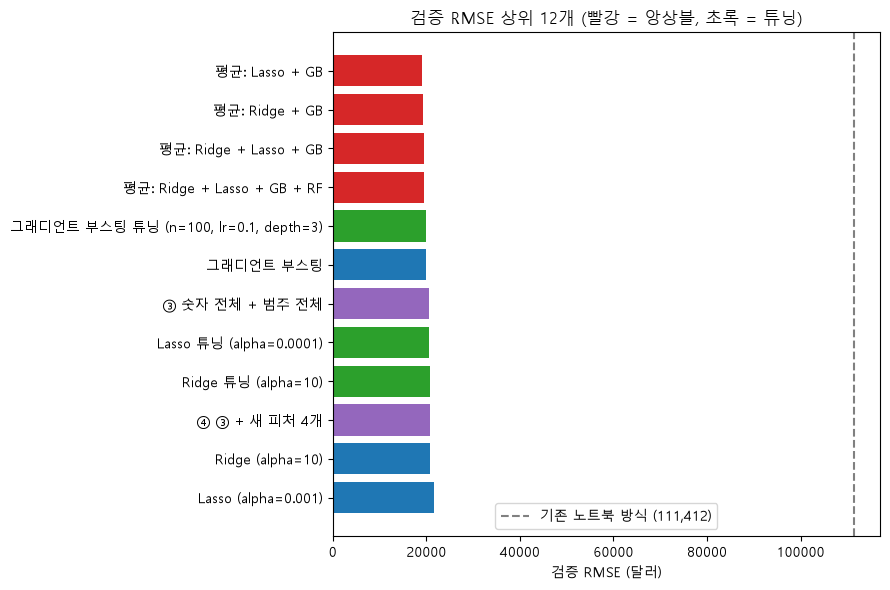

In [23]:
top_log = log.head(12).iloc[::-1]
colors = {"기준": "tab:gray", "피처 실험": "tab:purple", "모델 비교": "tab:blue", "튜닝": "tab:green", "앙상블": "tab:red"}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_log["실험"], top_log["검증 RMSE"], color=[colors.get(g, "tab:blue") for g in top_log["구분"]])
ax.axvline(old_rmse, color="gray", linestyle="--", label=f"기존 노트북 방식 ({old_rmse:,.0f})")
ax.set_xlabel("검증 RMSE (달러)")
ax.set_title("검증 RMSE 상위 12개 (빨강 = 앙상블, 초록 = 튜닝)")
ax.legend()
plt.tight_layout(); plt.show()

> **해석**: 앙상블이 단일 모델보다 검증 RMSE가 낮습니다. 기존 노트북 방식과 비교하면 오차가 절반 가까이 줄었습니다.

---
# 7. 최종 모델로 테스트 예측 및 제출 파일 만들기

1. 검증 RMSE가 가장 낮은 방법을 고릅니다.
2. 이번에는 검증용까지 포함한 **학습 데이터 전체**로 다시 학습합니다. 데이터가 많을수록 더 잘 배우기 때문입니다. 설정값은 위에서 고른 값을 그대로 씁니다.
3. 테스트 데이터를 예측하고 달러로 되돌려 `submission_v1.csv`로 저장합니다. (1차 제출 → 리더보드 RMSE **20,992**)

In [24]:
final_models = {
    "Ridge": make_pipeline(linear_preprocessor(), Ridge(alpha=best_ridge_alpha)),
    "Lasso": make_pipeline(linear_preprocessor(), Lasso(alpha=best_lasso_alpha, max_iter=50000)),
    "GB": make_pipeline(tree_preprocessor(), GradientBoostingRegressor(
        n_estimators=best_gb_n, learning_rate=best_gb_lr, max_depth=best_gb_depth, random_state=42)),
    "RF": make_pipeline(tree_preprocessor(), RandomForestRegressor(
        n_estimators=300, max_depth=best_rf_depth, max_features=best_rf_mf, random_state=42, n_jobs=-1)),
}

# 앙상블과 단일 튜닝 모델 중 검증 RMSE가 가장 낮은 것을 선택
candidates = {("평균: " + " + ".join(c)): c for c in combos}
candidates.update({tuned[k]: (k,) for k in tuned})
scores = log.set_index("실험")["검증 RMSE"]
best_name = min(candidates, key=lambda n: scores[n])
best_combo = candidates[best_name]
print("선택한 방법:", best_name, f"(검증 RMSE {scores[best_name]:,})")

test_preds = []
for k in best_combo:
    final_models[k].fit(X_all, y_all)                       # 학습 데이터 전체로 다시 학습
    test_preds.append(np.expm1(final_models[k].predict(X_test)))
final_pred = np.mean(test_preds, axis=0)

submission = pd.DataFrame({"Id": test["Id"], "SalePrice": final_pred})
submission.to_csv("submission_v1.csv", index=False)   # 1차 제출 파일 (리더보드 20,992)
submission.head()

선택한 방법: 평균: Lasso + GB (검증 RMSE 19,189)


,Id,SalePrice
0,86,280094.909361
1,227,261858.356508
2,492,145646.428453
3,64,136183.394001
4,576,117312.901734


### 제출 파일 점검

제출 전에 형식과 값이 정상인지 확인합니다.

행 수: 292 (sample: 292 )
열 이름: ['Id', 'SalePrice']
Id 순서가 sample과 같은가: True
빈 값: 0 개
0 이하(마이너스) 가격: 0 개
예측 가격 범위: 47,985 ~ 541,236


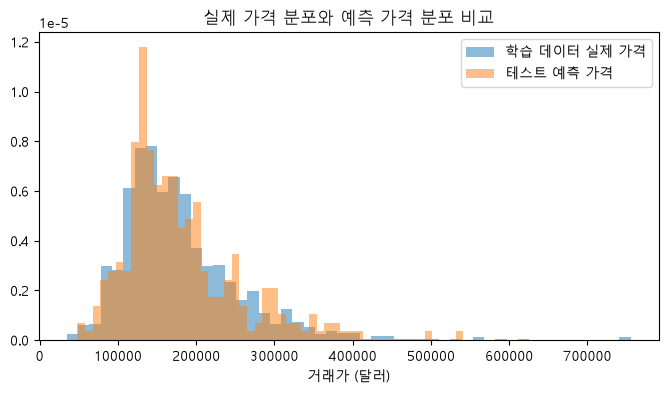

In [25]:
sample = pd.read_csv("sample_submission.csv")
check = pd.read_csv("submission_v1.csv")
print("행 수:", len(check), "(sample:", len(sample), ")")
print("열 이름:", check.columns.tolist())
print("Id 순서가 sample과 같은가:", bool((check["Id"].values == sample["Id"].values).all()))
print("빈 값:", int(check["SalePrice"].isna().sum()), "개")
print("0 이하(마이너스) 가격:", int((check["SalePrice"] <= 0).sum()), "개")
print("예측 가격 범위:", f"{check['SalePrice'].min():,.0f} ~ {check['SalePrice'].max():,.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train["SalePrice"], bins=50, alpha=0.5, density=True, label="학습 데이터 실제 가격")
ax.hist(check["SalePrice"], bins=50, alpha=0.5, density=True, label="테스트 예측 가격")
ax.set_xlabel("거래가 (달러)")
ax.set_title("실제 가격 분포와 예측 가격 분포 비교")
ax.legend(); plt.show()

---
# 8. 추가 개선: 교차 검증으로 더 믿을 수 있게 고르기

1차 제출(7단계)의 리더보드 RMSE는 **20,992**였습니다. 더 줄이기 위해 세 가지를 바꿉니다.

| 바꾼 것 | 이유 |
| --- | --- |
| **5-fold 교차 검증** | 검증용 234채 한 번으로는 운이 많이 섞입니다. 데이터를 5조각으로 나눠 **한 조각씩 돌아가며 검증용으로 쓰고** 5번의 결과를 합칩니다. 모든 집이 한 번씩 검증에 쓰여서 비교가 더 믿을 만해집니다 |
| **피처 추가 (v2)** | 품질 등급 글자를 숫자로 바꾼 피처 등 |
| **새 모델 SVR, 천천히 배우는 부스팅** | 서로 다른 방식의 모델을 섞으면 앙상블 효과가 커집니다 |

```
데이터 5조각:  [1][2][3][4][5]
1회차: 검증=[1]  학습=[2][3][4][5]
2회차: 검증=[2]  학습=[1][3][4][5]
...
5회차: 검증=[5]  학습=[1][2][3][4]
→ 집마다 "자기가 학습에 안 쓰였을 때의 예측"이 하나씩 생김 → 전체 RMSE 계산
```

In [26]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVR

kf = KFold(n_splits=5, shuffle=True, random_state=42)
y_dollar = np.expm1(y_all)

def cv_rmse(model, X):
    """5-fold 교차 검증. 집마다 '학습에 안 쓰였을 때의 예측'을 모아 RMSE(달러)를 계산합니다."""
    oof = np.zeros(len(X))
    for tr_idx, va_idx in kf.split(X):
        model.fit(X.iloc[tr_idx], y_all.iloc[tr_idx])
        oof[va_idx] = model.predict(X.iloc[va_idx])
    oof = np.expm1(oof)
    return np.sqrt(mean_squared_error(y_dollar, oof)), oof

def make_preprocessors(X):
    """피처 목록이 바뀌어도 쓸 수 있게 X를 받아 전처리기를 만듭니다. (규칙은 fit할 때 학습 조각에서만 배움)"""
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    skew = [c for c in num if X[c].min() >= 0 and abs(X[c].skew()) > 0.75]
    plain = [c for c in num if c not in skew]
    log = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
    def onehot():
        return make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
    def linear(scaler=StandardScaler):
        return ColumnTransformer([
            ("skew", make_pipeline(SimpleImputer(strategy="median"), log, scaler()), skew),
            ("num", make_pipeline(SimpleImputer(strategy="median"), scaler()), plain),
            ("cat", onehot(), cat)])
    def tree():
        return ColumnTransformer([("num", SimpleImputer(strategy="median"), num), ("cat", onehot(), cat)])
    return linear, tree

cv_log = []
def record(name, rmse):
    cv_log.append({"실험": name, "CV RMSE": round(rmse)})
    print(f"[{name}] CV RMSE {rmse:,.0f}")

### 8-1. 기준: 1차 제출 방법을 교차 검증으로 다시 채점

비교의 출발점입니다. 1차 제출 방법(Lasso + 그래디언트 부스팅 평균)의 CV RMSE를 구합니다.

In [27]:
lin1, tree1 = make_preprocessors(X_all)
r_l, oof_l1 = cv_rmse(make_pipeline(lin1(), Lasso(alpha=best_lasso_alpha, max_iter=50000)), X_all)
r_g, oof_g1 = cv_rmse(make_pipeline(tree1(), GradientBoostingRegressor(
    n_estimators=best_gb_n, learning_rate=best_gb_lr, max_depth=best_gb_depth, random_state=42)), X_all)
record("1차 제출 방법 (Lasso + GB 평균)", np.sqrt(mean_squared_error(y_dollar, (oof_l1 + oof_g1) / 2)))

[1차 제출 방법 (Lasso + GB 평균)] CV RMSE 22,181


> CV RMSE가 실제 리더보드 점수(20,992)와 비슷한 수준입니다. 그래서 교차 검증 점수를 믿고 개선 방향을 정할 수 있습니다.

### 8-2. 피처 추가 (v2)

| 새 피처 | 뜻 | 왜 도움이 될까 |
| --- | --- | --- |
| `ExterQual_n` 등 10개 | 품질 등급 Po/Fa/TA/Gd/Ex → 1/2/3/4/5, 없음 → 0 | 원핫 인코딩은 "Ex가 Gd보다 좋다"는 **순서**를 모릅니다. 숫자로 바꾸면 순서를 알려 줄 수 있습니다 |
| `TotalPorch` | 현관·데크 면적 합계 | 흩어진 작은 면적을 하나로 |
| `QualSF`, `QualTotalSF` | 품질 등급 × 면적 | "넓고 **그리고** 고급"인 집은 둘을 따로 볼 때보다 더 비쌉니다 |
| `HasGarage`, `HasBsmt`, `Has2nd`, `HasFireplace` | 시설이 있으면 1, 없으면 0 | "있다/없다" 자체가 가격 차이를 만듭니다 |
| `YrSold`, `MoSold` → 글자 | 팔린 연도·월 | 2008년 금융위기처럼 연도 효과는 직선이 아니라서 범주로 봅니다 |

In [28]:
QUAL_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
QUAL_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
             "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]

def prepare_v2(df):
    d = prepare(df)
    for c in QUAL_COLS:
        d[c + "_n"] = d[c].map(QUAL_MAP)
    d["TotalPorch"] = d[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
    d["QualSF"] = d["OverallQual"] * d["GrLivArea"]
    d["QualTotalSF"] = d["OverallQual"] * d["TotalSF"]
    d["HasGarage"] = (d["GarageArea"] > 0).astype(int)
    d["HasBsmt"] = (d["TotalBsmtSF"] > 0).astype(int)
    d["Has2nd"] = (d["2ndFlrSF"] > 0).astype(int)
    d["HasFireplace"] = (d["Fireplaces"] > 0).astype(int)
    d["YrSold"] = d["YrSold"].astype(str)
    d["MoSold"] = d["MoSold"].astype(str)
    return d

X2 = prepare_v2(train.drop(columns=["Id", "SalePrice"]))
X2_test = prepare_v2(test.drop(columns=["Id"]))
lin2, tree2 = make_preprocessors(X2)
print("v2 피처 수:", X2.shape[1], "(v1:", X_all.shape[1], ")")

for name, X, lin in [("v1 피처", X_all, lin1), ("v2 피처", X2, lin2)]:
    record(f"Lasso alpha=0.0001 · {name}", cv_rmse(make_pipeline(lin(), Lasso(alpha=0.0001, max_iter=50000)), X)[0])

v2 피처 수: 100 (v1: 83 )


[Lasso alpha=0.0001 · v1 피처] CV RMSE 22,059


[Lasso alpha=0.0001 · v2 피처] CV RMSE 21,496


> 같은 Lasso 모델인데 v2 피처를 쓰면 CV RMSE가 줄어듭니다. 이후 실험은 v2 피처로 진행합니다.

### 8-3. 새 모델: SVR

**SVR(서포트 벡터 회귀)**은 "예측이 정답에서 **허용 범위(epsilon) 안**이면 벌점을 주지 않고, 벗어난 것만 줄이자"는 모델입니다.
- `gamma`: 클수록 가까운 집만 보고 구불구불한 규칙을, 작을수록 넓게 보고 완만한 규칙을 만듭니다.
- `C`: 허용 범위를 벗어난 것에 대한 벌점 세기입니다. 크면 학습용을 더 꼼꼼히 맞추려 합니다.

SVR은 숫자 크기에 민감해서 스케일링이 꼭 필요합니다. 여기서는 이상한 값에 덜 흔들리는 `RobustScaler`(중앙값과 사분위 범위 기준)를 씁니다.

In [29]:
svr_grid = []
for C in [10, 20, 50, 100]:
    for g in [0.0001, 0.0003, 0.001]:
        r, _ = cv_rmse(make_pipeline(lin2(RobustScaler), SVR(C=C, gamma=g, epsilon=0.01)), X2)
        svr_grid.append({"C": C, "gamma": g, "CV RMSE": round(r)})
svr_grid = pd.DataFrame(svr_grid)
print(svr_grid.pivot(index="C", columns="gamma", values="CV RMSE"))
best_svr = svr_grid.loc[svr_grid["CV RMSE"].idxmin()]
best_svr_C, best_svr_g = int(best_svr["C"]), float(best_svr["gamma"])
svr_model = make_pipeline(lin2(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01))
r_svr, oof_svr = cv_rmse(svr_model, X2)
record(f"SVR (C={best_svr_C}, gamma={best_svr_g}) · v2", r_svr)

gamma  0.0001  0.0003  0.0010
C                            
10      22944   21248   20291
20      21763   20722   20468
50      21015   20066   21423
100     20602   20269   22516


[SVR (C=50, gamma=0.0003) · v2] CV RMSE 20,066


### 8-4. Lasso 다시 튜닝, 천천히 배우는 그래디언트 부스팅

부스팅에는 과적합을 막는 장치를 더합니다.
- `learning_rate`를 작게, 나무를 많이 → 천천히, 꼼꼼하게 학습
- `subsample=0.7`: 나무마다 집의 70%만 무작위로 봄
- `max_features="sqrt"`: 질문할 때 피처 일부만 고려
- `min_samples_leaf=5`: 마지막 칸에 집이 최소 5채 → 한두 채짜리 규칙을 외우지 않음
- `loss="huber"`: 크게 틀린 집에 너무 끌려가지 않는 오차 계산법

In [30]:
lasso_cv = {}
for a in [0.00005, 0.0001, 0.0002, 0.0005]:
    lasso_cv[a] = cv_rmse(make_pipeline(lin2(), Lasso(alpha=a, max_iter=50000)), X2)
best_lasso2 = min(lasso_cv, key=lambda a: lasso_cv[a][0])
r_lasso, oof_lasso = lasso_cv[best_lasso2]
print({a: round(v[0]) for a, v in lasso_cv.items()})
record(f"Lasso (alpha={best_lasso2}) · v2", r_lasso)

gb_cv = {}
for lr, n in [(0.1, 100), (0.02, 2000), (0.01, 4000)]:
    m = make_pipeline(tree2(), GradientBoostingRegressor(
        n_estimators=n, learning_rate=lr, max_depth=3, subsample=0.7, max_features="sqrt",
        min_samples_leaf=5, loss="huber", random_state=42))
    gb_cv[(lr, n)] = cv_rmse(m, X2)
    print(f"GB lr={lr}, 나무 {n}그루 → CV RMSE {gb_cv[(lr, n)][0]:,.0f}")
best_gb2 = min(gb_cv, key=lambda k: gb_cv[k][0])
r_gb, oof_gb = gb_cv[best_gb2]
record(f"GB 천천히 (lr={best_gb2[0]}, n={best_gb2[1]}) · v2", r_gb)

{5e-05: 21818, 0.0001: 21496, 0.0002: 21570, 0.0005: 21678}
[Lasso (alpha=0.0001) · v2] CV RMSE 21,496


GB lr=0.1, 나무 100그루 → CV RMSE 24,707


GB lr=0.02, 나무 2000그루 → CV RMSE 22,203


GB lr=0.01, 나무 4000그루 → CV RMSE 22,061
[GB 천천히 (lr=0.01, n=4000) · v2] CV RMSE 22,061


### 8-5. 가중 앙상블

이번에는 단순 평균이 아니라 **비율(가중치)**을 바꿔 가며 섞습니다. 예: SVR 50% + Lasso 20% + GB 30%. 0.1 단위로 합이 1이 되는 모든 조합(66가지)을 교차 검증 예측으로 채점해서 고릅니다.

In [31]:
P = {"SVR": oof_svr, "Lasso": oof_lasso, "GB": oof_gb}
weight_rows = []
for i in range(11):
    for j in range(11 - i):
        w_svr, w_lasso = i / 10, j / 10
        w_gb = round(1 - w_svr - w_lasso, 1)
        p = w_svr * P["SVR"] + w_lasso * P["Lasso"] + w_gb * P["GB"]
        weight_rows.append({"SVR": w_svr, "Lasso": w_lasso, "GB": w_gb,
                            "CV RMSE": round(np.sqrt(mean_squared_error(y_dollar, p)))})
weights = pd.DataFrame(weight_rows).sort_values("CV RMSE", ignore_index=True)
record("단순 평균 (SVR + Lasso + GB)", np.sqrt(mean_squared_error(y_dollar, (P["SVR"] + P["Lasso"] + P["GB"]) / 3)))
best_w = weights.iloc[0]
record(f"가중 평균 (SVR {best_w['SVR']}, Lasso {best_w['Lasso']}, GB {best_w['GB']})", best_w["CV RMSE"])
weights.head(8)

[단순 평균 (SVR + Lasso + GB)] CV RMSE 20,210
[가중 평균 (SVR 0.8, Lasso 0.0, GB 0.2)] CV RMSE 19,865


,SVR,Lasso,GB,CV RMSE
0,0.8,0.0,0.2,19865
1,0.7,0.0,0.3,19881
2,0.7,0.1,0.2,19886
3,0.6,0.1,0.3,19923
4,0.8,0.1,0.1,19926
5,0.9,0.0,0.1,19927
6,0.6,0.2,0.2,19944
7,0.7,0.2,0.1,19964


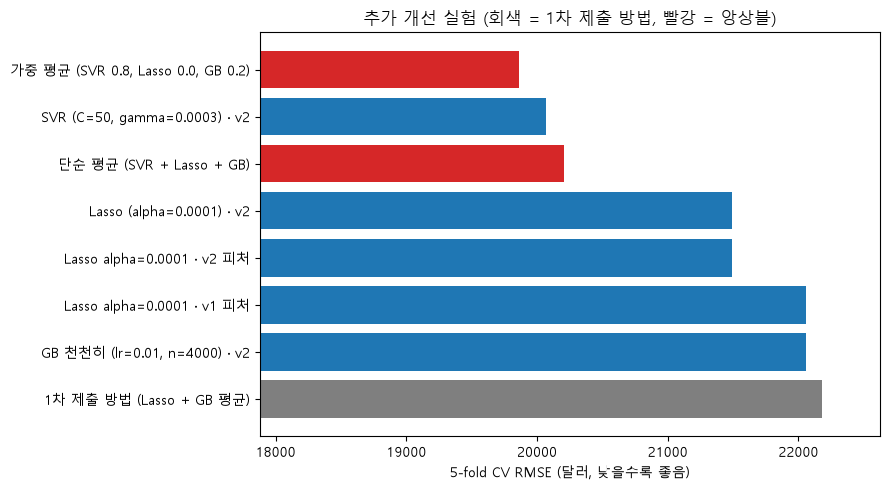

,실험,CV RMSE
0,"가중 평균 (SVR 0.8, Lasso 0.0, GB 0.2)",19865
1,"SVR (C=50, gamma=0.0003) · v2",20066
2,단순 평균 (SVR + Lasso + GB),20210
3,Lasso alpha=0.0001 · v2 피처,21496
4,Lasso (alpha=0.0001) · v2,21496
5,Lasso alpha=0.0001 · v1 피처,22059
6,"GB 천천히 (lr=0.01, n=4000) · v2",22061
7,1차 제출 방법 (Lasso + GB 평균),22181


In [32]:
cv_table = pd.DataFrame(cv_log).sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cv_table["실험"], cv_table["CV RMSE"],
        color=["tab:gray" if "1차" in n else ("tab:red" if "평균" in n else "tab:blue") for n in cv_table["실험"]])
ax.set_xlabel("5-fold CV RMSE (달러, 낮을수록 좋음)")
ax.set_title("추가 개선 실험 (회색 = 1차 제출 방법, 빨강 = 앙상블)")
ax.set_xlim(cv_table["CV RMSE"].min() * 0.9, cv_table["CV RMSE"].max() * 1.02)
plt.tight_layout(); plt.show()
cv_table.sort_values("CV RMSE", ignore_index=True)

> **해석**: 가장 크게 기여한 것은 **SVR**입니다. SVR은 선형 모델·트리 모델과 예측 방식이 달라서, 섞었을 때 서로의 실수를 잘 상쇄합니다. 가중치는 교차 검증 예측에 맞춰 고른 것이라 실제 리더보드에서는 이보다 조금 높게 나올 수 있습니다.

### 8-6. 최종 예측과 `submission_v2.csv` 저장 (2차 제출 → 리더보드 RMSE **19,421**)

세 모델을 **학습 데이터 전체**로 다시 학습한 뒤, 고른 가중치로 테스트 예측을 섞습니다.

In [33]:
final2 = {
    "SVR": svr_model,
    "Lasso": make_pipeline(lin2(), Lasso(alpha=best_lasso2, max_iter=50000)),
    "GB": make_pipeline(tree2(), GradientBoostingRegressor(
        n_estimators=best_gb2[1], learning_rate=best_gb2[0], max_depth=3, subsample=0.7, max_features="sqrt",
        min_samples_leaf=5, loss="huber", random_state=42)),
}
test_pred2 = np.zeros(len(X2_test))
for name, model in final2.items():
    if best_w[name] == 0:
        continue
    model.fit(X2, y_all)
    test_pred2 += best_w[name] * np.expm1(model.predict(X2_test))

submission2 = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred2})
submission2.to_csv("submission_v2.csv", index=False)   # 2차 제출 파일 (리더보드 19,421)

check = pd.read_csv("submission_v2.csv")
print("행 수:", len(check), "| Id 순서가 sample과 같은가:", bool((check["Id"].values == sample["Id"].values).all()))
print("빈 값:", int(check["SalePrice"].isna().sum()), "개 | 0 이하 가격:", int((check["SalePrice"] <= 0).sum()), "개")
print("예측 가격 범위:", f"{check['SalePrice'].min():,.0f} ~ {check['SalePrice'].max():,.0f}")
v1 = pd.read_csv("submission_v1.csv")
print(f"1차 제출과의 예측 차이: 평균 {np.abs(check['SalePrice'] - v1['SalePrice']).mean():,.0f}달러")
check.head()

행 수: 292 | Id 순서가 sample과 같은가: True
빈 값: 0 개 | 0 이하 가격: 0 개
예측 가격 범위: 55,235 ~ 577,716
1차 제출과의 예측 차이: 평균 5,235달러


,Id,SalePrice
0,86,264538.441602
1,227,272592.042360
2,492,145355.347844
3,64,135793.142837
4,576,116089.943170


---
# 9. 3차 개선: 이상치 정리 + 새 모델 KRR + 3개 분할로 확인

2차 제출(8단계)의 리더보드 RMSE는 **19,421**이었습니다. 더 줄이기 위해 아래를 시험했습니다.

| 시도 | 결과 |
| --- | --- |
| 피처 더 추가 (v3) | SVR 20,066 → 19,876 (**채택**) |
| 학습할 때만 이상한 집 빼기 | SVR·KRR은 좋아짐, GB 단독은 약간 나빠짐 (3개를 섞은 결과가 가장 좋아서 **채택**) |
| 새 모델 **KRR**(커널 릿지) | SVR과 비슷하게 강함 (**채택**) |
| 비싼 집에 가중치 주기 | KRR에서만 조금 좋아짐 (**KRR에만 채택**) |
| LightGBM (다른 부스팅 라이브러리) | 약 23,000으로 기존 부스팅보다 나빠서 제외 |

또 하나 알게 된 점: **교차 검증 점수도 데이터를 어떻게 5조각으로 나누느냐(seed)에 따라 ±500 정도 흔들립니다.**
그래서 마지막 비교는 **서로 다른 3가지 분할**에서 모두 해 보고 평균으로 판단합니다.

### 9-1. 피처 추가 (v3)

| 새 피처 / 변경 | 뜻 |
| --- | --- |
| `LotFrontage` 빈칸 → **같은 동네(Neighborhood)의 중앙값** | 도로에 닿은 길이는 동네마다 비슷하므로 전체 중앙값보다 정확합니다 |
| `Remodeled` | 리모델링을 한 적 있으면 1 |
| `IsNew` | 지은 지 1년 이내에 팔렸으면 1 (신축) |
| `OverallQual2` | 전체 품질의 제곱 → 품질이 높을수록 가격이 **더 가파르게** 오르는 것을 표현 |
| `GrLivArea_log` | 생활 면적의 로그 |
| `KitchenQualSF`, `ExterQualSF` | 부엌 품질 × 면적, 외장 품질 × 면적 |
| `GarageScore` | 차고 칸 수 × 차고 품질 |
| `Utilities`, `Street`, `PoolQC` **삭제** | 거의 모든 집이 같은 값이라 정보가 없음 |

In [34]:
def prepare_v3(df):
    d = prepare_v2(df)
    d["LotFrontage"] = d["LotFrontage"].fillna(d.groupby("Neighborhood")["LotFrontage"].transform("median"))
    d["Remodeled"] = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
    d["IsNew"] = (d["HouseAge"] <= 1).astype(int)
    d["OverallQual2"] = d["OverallQual"] ** 2
    d["GrLivArea_log"] = np.log1p(d["GrLivArea"])
    d["KitchenQualSF"] = d["KitchenQual_n"] * d["GrLivArea"]
    d["GarageScore"] = d["GarageCars"] * d["GarageQual_n"]
    d["ExterQualSF"] = d["ExterQual_n"] * d["GrLivArea"]
    return d.drop(columns=["Utilities", "Street", "PoolQC"])

X3 = prepare_v3(train.drop(columns=["Id", "SalePrice"]))
X3_test = prepare_v3(test.drop(columns=["Id"]))
lin3, tree3 = make_preprocessors(X3)
print("v3 피처 수:", X3.shape[1])

v3 피처 수: 104


### 9-2. 학습할 때만 이상한 집 빼기

2단계에서 눈에 띄는 이상치 2채를 뺐지만, 그 외에도 **"이 집 가격은 조건에 비해 너무 이상하다"** 싶은 집이 몇 채 있습니다.
이런 집은 모델이 엉뚱한 규칙을 배우게 만듭니다.

방법:
1. 학습 조각으로 간단한 Ridge 모델을 학습합니다.
2. 학습 조각 안에서 예측과 정답의 차이(잔차)가 **표준편차의 3배(또는 3.5배)보다 큰 집**을 찾습니다.
3. 그 집들을 빼고 진짜 모델(SVR 등)을 학습합니다.

⚠️ **검증 조각의 집은 하나도 빼지 않습니다.** 채점은 항상 모든 집으로 해야 공정합니다. (테스트 집도 우리가 고를 수 없으니까요)

### 9-3. 새 모델 KRR (커널 릿지)

**KRR(Kernel Ridge Regression)**은 Ridge에 "피처끼리 곱한 조합"을 자동으로 넣어 주는 모델입니다.
예를 들어 "면적 × 품질"처럼 두 피처가 **함께** 클 때의 효과를 스스로 찾아냅니다. (`kernel="polynomial", degree=2` = 2개씩 곱한 조합)

또 KRR은 학습할 때 **비싼 집에 가중치를 조금 더** 줍니다(`가격^0.5`에 비례).
채점은 달러 오차인데, 비싼 집은 조금만 틀려도 달러 오차가 크기 때문입니다.

In [35]:
from sklearn.kernel_ridge import KernelRidge

def cv_clean(make_model, X, lin, clean=None, wpow=0.0, seed=42):
    """5-fold CV. clean이 있으면 '학습 조각에서만' 잔차가 큰 집을 빼고 학습합니다. wpow>0이면 비싼 집에 가중치."""
    oof = np.zeros(len(X))
    for tr, va in KFold(5, shuffle=True, random_state=seed).split(X):
        if clean is not None:
            ridge = make_pipeline(lin(), Ridge(alpha=15)).fit(X.iloc[tr], y_all.iloc[tr])
            res = y_all.iloc[tr].values - ridge.predict(X.iloc[tr])
            tr = tr[np.abs(res - res.mean()) < clean * res.std()]     # 학습 조각에서만 뺌
        model = make_model()
        w = y_dollar.values[tr] ** wpow
        model.fit(X.iloc[tr], y_all.iloc[tr], **{model.steps[-1][0] + "__sample_weight": w / w.mean()})
        oof[va] = model.predict(X.iloc[va])                         # 검증 조각은 모든 집
    return np.expm1(oof)

def rmse_d(p):
    return np.sqrt(mean_squared_error(y_dollar, p))

# 모델 만드는 함수들 (매번 새 모델을 만들기 위해 함수로 둡니다)
new_models = {
    "SVR":  (lambda: make_pipeline(lin3(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01)), 3.5, 0.0),
    "KRR":  (lambda: make_pipeline(lin3(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)), 3.0, 0.5),
    "GB":   (lambda: make_pipeline(tree3(), GradientBoostingRegressor(
                n_estimators=4000, learning_rate=0.01, max_depth=3, subsample=0.7, max_features="sqrt",
                min_samples_leaf=5, loss="huber", random_state=42)), 3.0, 0.0),
}
print("이상치 빼기 효과 (seed 42):")
for name, (mk, clean, wpow) in new_models.items():
    before = rmse_d(cv_clean(mk, X3, lin3, None, wpow))
    after = rmse_d(cv_clean(mk, X3, lin3, clean, wpow))
    print(f"  {name}: 빼기 전 {before:,.0f} → 뺀 후 {after:,.0f}")

이상치 빼기 효과 (seed 42):


  SVR: 빼기 전 19,876 → 뺀 후 19,791


  KRR: 빼기 전 20,174 → 뺀 후 19,775


  GB: 빼기 전 21,705 → 뺀 후 21,859


### 9-4. 3가지 분할로 공정하게 비교

2차 제출 방법(SVR 80% + GB 20%, v2 피처)과 새 방법(SVR 40% + KRR 40% + GB 20%, v3 피처 + 이상치 정리)을
**같은 3가지 분할**에서 채점합니다. 세 번 모두 새 방법이 낮아야 진짜로 좋아진 것이라고 판단합니다.

> 비율 40/40/20은 여러 비율을 시험해 본 뒤, 결과가 비슷한 것들 중 **딱 떨어지는 단순한 값**으로 골랐습니다.
> 너무 세밀하게 맞춘 비율은 교차 검증에만 잘 맞고 테스트에서는 덜 맞을 수 있기 때문입니다.

In [36]:
W_NEW = {"SVR": 0.4, "KRR": 0.4, "GB": 0.2}
old_svr = lambda: make_pipeline(lin2(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01))
old_gb = lambda: make_pipeline(tree2(), GradientBoostingRegressor(
    n_estimators=best_gb2[1], learning_rate=best_gb2[0], max_depth=3, subsample=0.7, max_features="sqrt",
    min_samples_leaf=5, loss="huber", random_state=42))

seed_rows = []
for seed in [42, 2, 123]:
    old = best_w["SVR"] * cv_clean(old_svr, X2, lin2, seed=seed) + best_w["GB"] * cv_clean(old_gb, X2, lin2, seed=seed)
    oof3 = {n: cv_clean(mk, X3, lin3, clean, wpow, seed=seed) for n, (mk, clean, wpow) in new_models.items()}
    new = sum(W_NEW[n] * oof3[n] for n in W_NEW)
    seed_rows.append({"분할 seed": seed, "2차 제출 방법": round(rmse_d(old)), "3차 새 방법": round(rmse_d(new)),
                      **{f"{n} 단독": round(rmse_d(oof3[n])) for n in oof3}})
seed_table = pd.DataFrame(seed_rows).set_index("분할 seed")
seed_table.loc["평균"] = seed_table.mean().round()
record("3차: SVR.4 + KRR.4 + GB.2 · v3 + 이상치 정리", seed_table["3차 새 방법"].iloc[0])
seed_table

[3차: SVR.4 + KRR.4 + GB.2 · v3 + 이상치 정리] CV RMSE 19,440


,2차 제출 방법,3차 새 방법,SVR 단독,KRR 단독,GB 단독
분할 seed,,,,,
42,19865.0,19440.0,19791.0,19775.0,21859.0
2,20642.0,20131.0,20673.0,20569.0,21133.0
123,20583.0,20021.0,20660.0,20421.0,21528.0
평균,20363.0,19864.0,20375.0,20255.0,21507.0


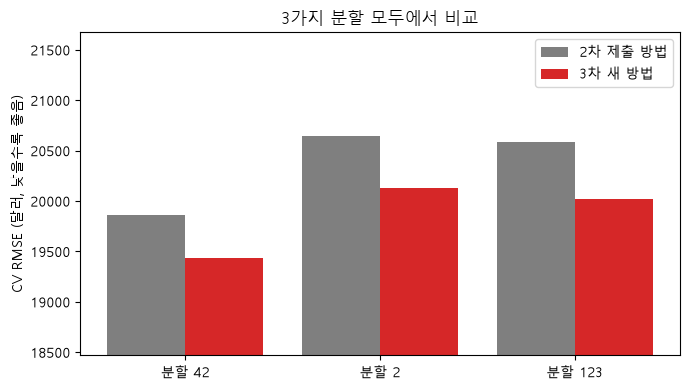

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(3)
ax.bar(xs - 0.2, seed_table["2차 제출 방법"].iloc[:3], width=0.4, label="2차 제출 방법", color="tab:gray")
ax.bar(xs + 0.2, seed_table["3차 새 방법"].iloc[:3], width=0.4, label="3차 새 방법", color="tab:red")
ax.set_xticks(xs); ax.set_xticklabels([f"분할 {s}" for s in [42, 2, 123]])
ax.set_ylim(seed_table[["2차 제출 방법", "3차 새 방법"]].values.min() * 0.95, None)
ax.set_ylabel("CV RMSE (달러, 낮을수록 좋음)"); ax.legend(); ax.set_title("3가지 분할 모두에서 비교")
plt.tight_layout(); plt.show()

> **해석**: 세 가지 분할 **모두에서** 새 방법이 2차 제출 방법보다 낮습니다(약 2~3%).
> 한 번만 좋아진 게 아니라 꾸준히 좋아졌으므로, 운이 아니라 실제 개선이라고 볼 수 있습니다.
> KRR 단독 점수가 SVR과 비슷하게 좋고, 둘은 예측 방식이 달라서 섞었을 때 효과가 큽니다.

### 9-5. 최종 예측과 `submission_v3.csv` 저장 (3차 제출 → 리더보드 RMSE **19,135**)

1. 학습 데이터 **전체**로 Ridge를 학습해서 잔차가 큰 집을 찾아 뺍니다 (모델마다 기준 3.0 / 3.5).
2. SVR, KRR, GB를 다시 학습합니다.
3. 테스트 예측을 40% / 40% / 20%로 섞어 `submission_v3.csv`로 저장합니다.

In [38]:
ridge_full = make_pipeline(lin3(), Ridge(alpha=15)).fit(X3, y_all)
res_full = y_all.values - ridge_full.predict(X3)
test_pred3 = np.zeros(len(X3_test))
for name, (mk, clean, wpow) in new_models.items():
    keep = np.abs(res_full - res_full.mean()) < clean * res_full.std()
    w = y_dollar.values[keep] ** wpow
    model = mk()
    model.fit(X3[keep], y_all[keep], **{model.steps[-1][0] + "__sample_weight": w / w.mean()})
    test_pred3 += W_NEW[name] * np.expm1(model.predict(X3_test))
    print(f"{name}: 학습에서 뺀 집 {int((~keep).sum())}채, 비율 {W_NEW[name]}")

submission3 = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred3})
submission3.to_csv("submission_v3.csv", index=False)   # 3차 제출 파일 (리더보드 19,135)

check = pd.read_csv("submission_v3.csv")
print("행 수:", len(check), "| Id 순서가 sample과 같은가:", bool((check["Id"].values == sample["Id"].values).all()))
print("빈 값:", int(check["SalePrice"].isna().sum()), "개 | 0 이하 가격:", int((check["SalePrice"] <= 0).sum()), "개")
print("예측 가격 범위:", f"{check['SalePrice'].min():,.0f} ~ {check['SalePrice'].max():,.0f}")
v2 = pd.read_csv("submission_v2.csv")
print(f"2차 제출과의 예측 차이: 평균 {np.abs(check['SalePrice'] - v2['SalePrice']).mean():,.0f}달러")
check.head()

SVR: 학습에서 뺀 집 11채, 비율 0.4
KRR: 학습에서 뺀 집 19채, 비율 0.4


GB: 학습에서 뺀 집 19채, 비율 0.2
행 수: 292 | Id 순서가 sample과 같은가: True
빈 값: 0 개 | 0 이하 가격: 0 개
예측 가격 범위: 62,719 ~ 588,881
2차 제출과의 예측 차이: 평균 2,406달러


,Id,SalePrice
0,86,263078.040837
1,227,269240.599845
2,492,143679.370268
3,64,132427.234222
4,576,112859.299845


---
# 10. 4차 개선: 크게 틀리는 집 분석 → 더 다양한 모델 섞기

3차 제출(9단계)의 리더보드 RMSE는 **19,135**였습니다.

### 10-1. 어떤 집에서 크게 틀리나?

교차 검증 예측에서 오차가 큰 집을 살펴보면, **거래 조건(SaleCondition)이 `Partial`(신축 분양)**인 집의 오차가 일반 거래(`Normal`)의 약 2.5배입니다.
분양 집은 공사가 끝나기 전에 계약한 가격이라 들쭉날쭉하고, 위로도 아래로도 틀립니다. 그래서 한쪽으로 보정할 수는 없습니다.
→ **예측 방식이 서로 다른 모델을 더 섞어** 서로의 실수를 상쇄시키는 쪽을 택합니다.

In [39]:
ref = (0.4 * oof3["SVR"] + 0.4 * oof3["KRR"] + 0.2 * oof3["GB"])   # 9단계 마지막 분할(seed 123)의 3차 방법 예측
err_df = pd.DataFrame({"거래 조건": train["SaleCondition"], "오차": ref - y_dollar.values})
summary_err = err_df.groupby("거래 조건")["오차"].agg(집_수="size", RMSE=lambda e: np.sqrt((e ** 2).mean())).round()
print(summary_err.sort_values("RMSE", ascending=False))
big = np.argsort(-np.abs(err_df["오차"].values))[:20]
print("\n오차가 가장 큰 20채 중 Partial(신축 분양):", int((err_df["거래 조건"].values[big] == "Partial").sum()), "채")

         집_수     RMSE
거래 조건                
Partial   97  40342.0
Alloca    11  39476.0
Family    17  33964.0
Abnorml   78  22938.0
Normal   959  15518.0
AdjLand    4  14242.0

오차가 가장 큰 20채 중 Partial(신축 분양): 10 채


### 10-2. 새 재료 두 가지

| 새 재료 | 뜻 |
| --- | --- |
| **KRR + 남은 오차 부스팅** | 먼저 KRR이 예측하고, KRR이 **틀린 만큼(잔차)**을 그래디언트 부스팅이 한 번 더 배워서 고칩니다. 선형 계열이 잘 못하는 "조건이 겹칠 때 갑자기 달라지는 부분"을 나무가 보완합니다 |
| **잡음 피처 뺀 버전 (v3_drop)** | 팔린 월·연도, 거의 모든 집이 같은 값인 피처 등 12개를 뺀 데이터. 같은 모델이라도 **다른 데이터를 보면 실수하는 곳이 달라져서** 섞을 때 도움이 됩니다 |

⚠️ 잔차를 배울 때 KRR이 **학습한 집에 대한 예측**을 쓰면 잔차가 거의 0이라 배울 게 없습니다(이미 외웠으니까요).
그래서 학습 데이터 안에서도 다시 5조각으로 나눠 **"KRR이 안 본 집에 대한 예측"의 잔차**를 부스팅이 배우게 합니다.

In [40]:
import copy

DROP_COLS = ["MoSold", "YrSold", "Condition2", "RoofMatl", "Heating", "MiscFeature", "MiscVal",
             "LowQualFinSF", "3SsnPorch", "PoolArea", "Electrical", "Functional"]
X3d = X3.drop(columns=DROP_COLS)
X3d_test = X3_test.drop(columns=DROP_COLS)
lin3d, tree3d = make_preprocessors(X3d)

class KRRPlusResidualGB:
    """KRR로 먼저 예측하고, KRR이 '안 본 집'에서 틀린 만큼을 그래디언트 부스팅이 배웁니다."""
    def __init__(self, base, booster):
        self.base, self.booster = base, booster
    def fit(self, X, y, sample_weight=None):
        y = np.asarray(y)
        self.base.fit(X, y)
        inner = np.zeros(len(X))
        for a, b in KFold(5, shuffle=True, random_state=0).split(X):      # 학습 데이터 안에서 다시 5조각
            inner[b] = copy.deepcopy(self.base).fit(X.iloc[a], y[a]).predict(X.iloc[b])
        self.booster.fit(X, y - inner)                                   # 남은 오차(잔차)를 학습
        return self
    def predict(self, X):
        return self.base.predict(X) + self.booster.predict(X)

class NoWeight:
    """sample_weight 인자를 무시하는 얇은 포장 (cv_clean과 함께 쓰기 위해)"""
    def __init__(self, m): self.m = m; self.steps = [("m", self)]
    def fit(self, X, y, m__sample_weight=None): self.m.fit(X, y); return self
    def predict(self, X): return self.m.predict(X)

models4 = {
    "SVR":            (X3,  X3_test,  lin3,  lambda: make_pipeline(lin3(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01)), 3.5, 0.0),
    "KRR+잔차GB":     (X3,  X3_test,  lin3,  lambda: NoWeight(KRRPlusResidualGB(
                          make_pipeline(lin3(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)),
                          make_pipeline(tree3(), GradientBoostingRegressor(n_estimators=300, learning_rate=0.01, max_depth=3, subsample=0.7,
                                        max_features="sqrt", min_samples_leaf=10, loss="huber", random_state=42)))), 3.0, 0.0),
    "KRR (v3_drop)":  (X3d, X3d_test, lin3d, lambda: make_pipeline(lin3d(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)), 3.0, 0.5),
    "GB (v3_drop)":   (X3d, X3d_test, lin3d, lambda: make_pipeline(tree3d(), GradientBoostingRegressor(n_estimators=4000, learning_rate=0.01, max_depth=3,
                          subsample=0.7, max_features="sqrt", min_samples_leaf=5, loss="huber", random_state=42)), 3.0, 0.0),
}
W4 = {"SVR": 0.3, "KRR+잔차GB": 0.3, "KRR (v3_drop)": 0.2, "GB (v3_drop)": 0.2}

### 10-3. 3가지 분할로 3차 방법과 비교

9단계와 **같은 3가지 분할**에서 채점합니다. (몇 분 걸립니다)

> 비율 30/30/20/20은 여러 단순한 비율을 시험해 고른 값입니다. 자동으로 최적 비율을 찾는 방법(NNLS)도 시험했지만,
> 비율을 고른 집과 채점한 집을 분리해 확인하니 3차 방법과 비슷한 수준이었습니다. 그래서 **세밀하게 맞춘 비율 대신 단순한 비율**을 씁니다.

In [41]:
rows4 = []
for i, seed in enumerate([42, 2, 123]):
    oof4 = {n: cv_clean(mk, X, lin, clean, wpow, seed=seed) for n, (X, _, lin, mk, clean, wpow) in models4.items()}
    blend4 = sum(W4[n] * oof4[n] for n in W4)
    rows4.append({"분할 seed": seed, "3차 방법": seed_table["3차 새 방법"].iloc[i], "4차 방법": round(rmse_d(blend4)),
                  **{f"{n} 단독": round(rmse_d(oof4[n])) for n in oof4}})
table4 = pd.DataFrame(rows4).set_index("분할 seed")
table4.loc["평균"] = table4.mean().round()
record("4차: SVR.3 + KRR잔차GB.3 + KRR(drop).2 + GB(drop).2", table4["4차 방법"].iloc[0])
table4

[4차: SVR.3 + KRR잔차GB.3 + KRR(drop).2 + GB(drop).2] CV RMSE 19,253


,3차 방법,4차 방법,SVR 단독,KRR+잔차GB 단독,KRR (v3_drop) 단독,GB (v3_drop) 단독
분할 seed,,,,,,
42,19440.0,19253.0,19791.0,19560.0,19729.0,21600.0
2,20131.0,19882.0,20673.0,20319.0,20262.0,20937.0
123,20021.0,19943.0,20660.0,20294.0,20527.0,21672.0
평균,19864.0,19693.0,20375.0,20058.0,20173.0,21403.0


> **해석**: 세 가지 분할 **모두에서** 4차 방법이 3차 방법보다 낮습니다. 개선 폭은 약 1%로 크지 않습니다.
> 오차의 큰 부분이 신축 분양 집처럼 **원래 예측하기 어려운 집**에서 나오기 때문에, 모델을 바꿔서 줄일 수 있는 여지가 점점 작아지고 있습니다.

### 10-4. 최종 예측과 `submission_v4.csv` 저장 (4차 제출 → 리더보드 RMSE **18,965**)

In [42]:
test_pred4 = np.zeros(len(X3_test))
for name, (X, X_te, lin, mk, clean, wpow) in models4.items():
    ridge_full = make_pipeline(lin(), Ridge(alpha=15)).fit(X, y_all)
    res_full = y_all.values - ridge_full.predict(X)
    keep = np.abs(res_full - res_full.mean()) < clean * res_full.std()
    w = y_dollar.values[keep] ** wpow
    model = mk()
    model.fit(X[keep], y_all[keep], **{model.steps[-1][0] + "__sample_weight": w / w.mean()})
    test_pred4 += W4[name] * np.expm1(model.predict(X_te))
    print(f"{name}: 학습에서 뺀 집 {int((~keep).sum())}채, 비율 {W4[name]}")

submission4 = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred4})
submission4.to_csv("submission_v4.csv", index=False)   # 4차 제출 파일 (리더보드 18,965)

check = pd.read_csv("submission_v4.csv")
print("행 수:", len(check), "| Id 순서가 sample과 같은가:", bool((check["Id"].values == sample["Id"].values).all()))
print("빈 값:", int(check["SalePrice"].isna().sum()), "개 | 0 이하 가격:", int((check["SalePrice"] <= 0).sum()), "개")
print("예측 가격 범위:", f"{check['SalePrice'].min():,.0f} ~ {check['SalePrice'].max():,.0f}")
v3 = pd.read_csv("submission_v3.csv")
print(f"3차 제출과의 예측 차이: 평균 {np.abs(check['SalePrice'] - v3['SalePrice']).mean():,.0f}달러")
check.head()

SVR: 학습에서 뺀 집 11채, 비율 0.3


KRR+잔차GB: 학습에서 뺀 집 19채, 비율 0.3
KRR (v3_drop): 학습에서 뺀 집 18채, 비율 0.2


GB (v3_drop): 학습에서 뺀 집 18채, 비율 0.2
행 수: 292 | Id 순서가 sample과 같은가: True
빈 값: 0 개 | 0 이하 가격: 0 개
예측 가격 범위: 62,064 ~ 602,094
3차 제출과의 예측 차이: 평균 1,071달러


,Id,SalePrice
0,86,264332.349502
1,227,268433.460623
2,492,143317.747567
3,64,134505.004787
4,576,113161.352780


---
# 11. 5차 개선: 피처 다시 설계하기 (순서 인코딩 + 면적)

4차 제출(10단계)의 리더보드 RMSE는 **18,965**였습니다. 이후 두 가지를 더 시도했습니다.

| 시도 | 교차 검증 | 리더보드 | 결론 |
| --- | --- | --- | --- |
| 피처 log 변환 기준 0.75 → 3.0 | 크게 좋아짐 (약 −3.5%) | 19,006 (나빠짐) | 이 노트북에서는 쓰지 않음 |
| 위 방법 + 동네 시세 피처 | 조금 더 좋아짐 | 19,133 (나빠짐) | 이 노트북에서는 쓰지 않음 |

교차 검증이 좋아졌는데 리더보드는 두 번 연속 나빠졌습니다. 그래서 이번에는 **판정 기준을 더 엄격하게** 정했습니다.

> 피처를 바꿨을 때 **4차 방식의 모델(SVR, KRR)**과 **위의 "log 기준 3.0" 방식 모델(SVR, KRR)** 4개가 **모두** 좋아져야 채택한다.

모델 설정이 달라져도 일관되게 도움이 되는 변화만 남기려는 것입니다.

### 11-1. 순서가 있는 범주를 숫자로 바꾸기

지금까지 `BsmtExposure`(지하 노출: 없음 < 조금 < 보통 < 좋음) 같은 범주는 원핫 인코딩만 했습니다.
원핫은 "없음"과 "좋음"이 얼마나 다른지 모릅니다. **순서를 숫자로** 넣으면 모델이 "좋을수록 비싸다"를 바로 배울 수 있습니다.
(원핫 열은 그대로 두고, 숫자 열 `_o`를 **추가**합니다.)

| 묶음 | 열 | 순서 |
| --- | --- | --- |
| 1차 | `BsmtExposure`, `BsmtFinType1/2`, `GarageFinish`, `Functional`, `Fence`, `LotShape`, `LandSlope`, `PavedDrive`, `CentralAir` | 설명서에 순서가 적힌 열 |
| 2차 | `MasVnrType`, `Alley`, `MSZoning`, `GarageType`, `Foundation`, `SaleCondition`, `HouseStyle` | 상식적인 순서 (예: 기초 공사 슬래브 < 블록 < 콘크리트, 층수 1층 < 1.5층 < 2층) |

### 11-2. 면적 다시 설계하기

| 새 피처 | 뜻 |
| --- | --- |
| `FinishedSF`, `QualFinSF` | 마감된 면적(지상 + 마감된 지하)과 품질 × 마감 면적 |
| `AvgRoomSF` | 방 하나의 평균 크기 |
| `BathPerBed` | 침실당 욕실 수 |
| `LotArea_log` | 대지 면적의 로그 |
| `GarageAreaPerCar` | 차 1대당 차고 면적 |

In [43]:
ORD1 = {
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "LotShape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "LandSlope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "CentralAir": {"N": 0, "Y": 1},
}
ORD2 = {
    "MasVnrType": {"None": 0, "BrkCmn": 1, "BrkFace": 2, "Stone": 3},
    "Alley": {"None": 1, "Grvl": 0, "Pave": 2},
    "MSZoning": {"C (all)": 0, "RH": 1, "RM": 2, "RL": 3, "FV": 4},
    "GarageType": {"None": 0, "CarPort": 1, "Detchd": 2, "2Types": 3, "Basment": 3, "Attchd": 4, "BuiltIn": 5},
    "Foundation": {"Slab": 0, "Stone": 1, "BrkTil": 1, "CBlock": 2, "Wood": 2, "PConc": 3},
    "SaleCondition": {"AdjLand": 0, "Abnorml": 1, "Family": 1, "Alloca": 2, "Normal": 2, "Partial": 3},
    "HouseStyle": {"1Story": 1, "1.5Unf": 1.25, "1.5Fin": 1.5, "SFoyer": 1.5, "SLvl": 1.5, "2Story": 2, "2.5Unf": 2.25, "2.5Fin": 2.5},
}

def add_features(d, steps):
    """v3 피처(d)에 11단계 피처를 더합니다. steps: {"ord1", "ord2", "area"} 중 고른 것"""
    d = d.copy()
    if "ord1" in steps:
        for c, mp in ORD1.items():
            d[c + "_o"] = d[c].fillna("None").map(mp).fillna(0)
    if "ord2" in steps:
        for c, mp in ORD2.items():   # 설명서에 없는 값이 오면 중간값으로
            d[c + "_o"] = d[c].fillna("None").map(mp).fillna(np.median(list(mp.values())))
    if "area" in steps:
        d["FinBsmtSF"] = d["BsmtFinSF1"] + d["BsmtFinSF2"]
        d["FinishedSF"] = d["GrLivArea"] + d["FinBsmtSF"]
        d["QualFinSF"] = d["OverallQual"] * d["FinishedSF"]
        d["AvgRoomSF"] = d["GrLivArea"] / d["TotRmsAbvGrd"].clip(lower=1)
        d["BathPerBed"] = d["TotalBath"] / d["BedroomAbvGr"].clip(lower=1)
        d["LotArea_log"] = np.log1p(d["LotArea"])
        d["GarageAreaPerCar"] = d["GarageArea"] / d["GarageCars"].clip(lower=1)
    return d

def cv_clean_base(make_model, X, clean_X, clean_lin, clean, wpow, seed):
    """cv_clean과 같지만, '이상한 집' 판단은 원래 v3 피처(clean_X)로 고정합니다.
    → 같은 집을 빼고 비교하므로, 점수 차이는 순수하게 피처 변경 때문입니다."""
    oof = np.zeros(len(X))
    for tr, va in KFold(5, shuffle=True, random_state=seed).split(X):
        ridge = make_pipeline(clean_lin(), Ridge(alpha=15)).fit(clean_X.iloc[tr], y_all.iloc[tr])
        res = y_all.iloc[tr].values - ridge.predict(clean_X.iloc[tr])
        tr = tr[np.abs(res - res.mean()) < clean * res.std()]
        model = make_model()
        w = y_dollar.values[tr] ** wpow
        model.fit(X.iloc[tr], y_all.iloc[tr], **{model.steps[-1][0] + "__sample_weight": w / w.mean()})
        oof[va] = model.predict(X.iloc[va])
    return np.expm1(oof)

### 11-3. 피처를 하나씩 더하며 확인하기

빠르게 비교하기 위해 4차 조합 중 **SVR과 KRR(v3_drop)**만 써서, 피처 묶음을 하나씩 더할 때 3가지 분할의 CV RMSE가 어떻게 바뀌는지 봅니다.

In [44]:
steps_list = [("v3 (4차 피처)", set()), ("+ 순서 인코딩 1차", {"ord1"}),
              ("+ 순서 인코딩 2차", {"ord1", "ord2"}), ("+ 면적 재설계", {"ord1", "ord2", "area"})]
feat_rows = []
for label, steps in steps_list:
    Xf = add_features(X3, steps); Xfd = Xf.drop(columns=DROP_COLS)
    linf, _ = make_preprocessors(Xf); linfd, _ = make_preprocessors(Xfd)
    row = {"피처": label, "피처 수": Xf.shape[1]}
    for mname, Xv, mk, cX, cl, clean, wpow in [
        ("SVR", Xf, lambda: make_pipeline(linf(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01)), X3, lin3, 3.5, 0.0),
        ("KRR(v3_drop)", Xfd, lambda: make_pipeline(linfd(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)), X3d, lin3d, 3.0, 0.5)]:
        r = [rmse_d(cv_clean_base(mk, Xv, cX, cl, clean, wpow, s)) for s in [42, 2, 123]]
        row[f"{mname} 평균"] = round(np.mean(r))
        row[f"{mname} 분할별"] = " / ".join(f"{x:,.0f}" for x in r)
    feat_rows.append(row)
feat_table = pd.DataFrame(feat_rows)
feat_table

,피처,피처 수,SVR 평균,SVR 분할별,KRR(v3_drop) 평균,KRR(v3_drop) 분할별
0,v3 (4차 피처),104,20375,"19,791 / 20,673 / 20,660",20173,"19,729 / 20,262 / 20,527"
1,+ 순서 인코딩 1차,114,20328,"19,806 / 20,563 / 20,616",20014,"19,554 / 20,115 / 20,374"
2,+ 순서 인코딩 2차,121,20246,"19,756 / 20,463 / 20,519",19819,"19,368 / 19,937 / 20,152"
3,+ 면적 재설계,128,20047,"19,566 / 20,225 / 20,352",19747,"19,282 / 19,827 / 20,133"


> **해석**
> - 순서 인코딩 1차, 2차를 더할 때마다 SVR과 KRR이 모두 좋아집니다. 원핫 열만 있을 때보다 "좋을수록 비싸다"는 정보를 더 직접 받기 때문입니다.
> - 면적 재설계는 이 두 모델(4차 방식)에서는 좋아졌지만, "log 기준 3.0" 방식 모델에서는 나빠졌습니다(아래 표). 그래서 **근거가 가장 약한 변경**입니다.
>
> 5가지 분할로 확인한 전체 시도 결과입니다 (4차 방식 모델 2개 + log 기준 3.0 방식 모델 2개 = 4개 모델 기준).
>
> | 시도 | 결과 |
> | --- | --- |
> | 순서 인코딩 1차 | **채택** (4개 모델 모두 개선) |
> | 순서 인코딩 2차 | **채택** (4개 모델 모두, 5가지 분할 전부 개선) |
> | 면적 재설계 | 4차 방식 2개만 개선 → 4차 조합에서만 사용 |
> | 시간 재설계 (판매 시점 연속값, 연식 로그) | 기각 (4개 모두 나빠짐) |
> | 품질 종합 점수 | 기각 |
> | 희귀 범주를 "기타"로 합치기 | 기각 |
> | 순서 인코딩 3차 (건물 형태, 외장재 등) | 기각 |
> | 숫자로 바꾼 범주의 원핫 열 빼기 | 기각 |
> | 동네 시세 피처 | 기각 |
> | 새 피처에 맞춰 SVR·KRR 설정 다시 맞추기 | 차이가 작고 분할마다 달라 기존 설정 유지 |

### 11-4. 4차 조합 전체에 새 피처 넣기

10단계의 4차 조합(SVR 30% + KRR잔차GB 30% + KRR(v3_drop) 20% + GB(v3_drop) 20%)을 **그대로** 두고, 피처만 바꿉니다. (몇 분 걸립니다)

In [45]:
STEPS11 = {"ord1", "ord2", "area"}
X11, X11_test = add_features(X3, STEPS11), add_features(X3_test, STEPS11)
X11d, X11d_test = X11.drop(columns=DROP_COLS), X11_test.drop(columns=DROP_COLS)
lin11, tree11 = make_preprocessors(X11)
lin11d, tree11d = make_preprocessors(X11d)

models11 = {   # 이름: (X, X_test, 이상치 판단용 X, 이상치 판단용 전처리, 모델, 기준, 가중치 지수)
    "SVR":           (X11,  X11_test,  X3,  lin3,  lambda: make_pipeline(lin11(RobustScaler), SVR(C=best_svr_C, gamma=best_svr_g, epsilon=0.01)), 3.5, 0.0),
    "KRR+잔차GB":    (X11,  X11_test,  X3,  lin3,  lambda: NoWeight(KRRPlusResidualGB(
                         make_pipeline(lin11(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)),
                         make_pipeline(tree11(), GradientBoostingRegressor(n_estimators=300, learning_rate=0.01, max_depth=3, subsample=0.7,
                                       max_features="sqrt", min_samples_leaf=10, loss="huber", random_state=42)))), 3.0, 0.0),
    "KRR (v3_drop)": (X11d, X11d_test, X3d, lin3d, lambda: make_pipeline(lin11d(), KernelRidge(alpha=0.1, kernel="polynomial", degree=2, coef0=2.5)), 3.0, 0.5),
    "GB (v3_drop)":  (X11d, X11d_test, X3d, lin3d, lambda: make_pipeline(tree11d(), GradientBoostingRegressor(n_estimators=4000, learning_rate=0.01, max_depth=3,
                         subsample=0.7, max_features="sqrt", min_samples_leaf=5, loss="huber", random_state=42)), 3.0, 0.0),
}

rows11 = []
for i, seed in enumerate([42, 2, 123]):
    oof11 = {n: cv_clean_base(mk, X, cX, cl, clean, wpow, seed) for n, (X, _, cX, cl, mk, clean, wpow) in models11.items()}
    rows11.append({"분할 seed": seed, "4차 방법": table4["4차 방법"].iloc[i],
                   "5차 방법 (11단계)": round(rmse_d(sum(W4[n] * oof11[n] for n in W4))),
                   **{f"{n} 단독": round(rmse_d(oof11[n])) for n in oof11}})
table11 = pd.DataFrame(rows11).set_index("분할 seed")
table11.loc["평균"] = table11.mean().round()
record("5차: 4차 조합 + 순서 인코딩 + 면적 재설계", table11["5차 방법 (11단계)"].iloc[0])
table11

[5차: 4차 조합 + 순서 인코딩 + 면적 재설계] CV RMSE 18,964


,4차 방법,5차 방법 (11단계),SVR 단독,KRR+잔차GB 단독,KRR (v3_drop) 단독,GB (v3_drop) 단독
분할 seed,,,,,,
42,19253.0,18964.0,19566.0,19084.0,19282.0,21983.0
2,19882.0,19528.0,20225.0,19891.0,19827.0,20899.0
123,19943.0,19648.0,20352.0,19926.0,20133.0,21741.0
평균,19693.0,19380.0,20048.0,19634.0,19747.0,21541.0


> **해석**: 모델과 비율은 4차와 똑같고 피처만 바꿨는데, 세 분할 **모두에서** CV RMSE가 낮아졌습니다.
>
> 리더보드에서도 같은 방향이었습니다. 4차 조합에 피처를 하나씩 더한 파일을 제출한 결과입니다.
>
> | 파일 | 피처 | 리더보드 RMSE |
> | --- | --- | --- |
> | 4차 (`submission_v4.csv`) | v3 | 18,965.27 |
> | + 순서 인코딩 1차 | v3 + ord1 | 18,539.63 |
> | + 순서 인코딩 2차 | v3 + ord1 + ord2 | 18,413.44 |
> | **+ 면적 재설계 (`submission.csv`)** | v3 + ord1 + ord2 + area | 이 노트북의 최종 파일 |
>
> 리더보드는 292채로만 채점하므로, 교차 검증보다 크게 흔들릴 수 있습니다.

### 11-5. 최종 예측과 `submission.csv` 저장

In [46]:
test_pred11 = np.zeros(len(X11_test))
for name, (X, X_te, cX, cl, mk, clean, wpow) in models11.items():
    ridge_full = make_pipeline(cl(), Ridge(alpha=15)).fit(cX, y_all)     # 이상한 집 판단은 원래 피처로
    res_full = y_all.values - ridge_full.predict(cX)
    keep = np.abs(res_full - res_full.mean()) < clean * res_full.std()
    w = y_dollar.values[keep] ** wpow
    model = mk()
    model.fit(X[keep], y_all[keep], **{model.steps[-1][0] + "__sample_weight": w / w.mean()})
    test_pred11 += W4[name] * np.expm1(model.predict(X_te))
    print(f"{name}: 학습에서 뺀 집 {int((~keep).sum())}채, 비율 {W4[name]}")

submission11 = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred11})
submission11.to_csv("submission.csv", index=False)

check = pd.read_csv("submission.csv")
print("행 수:", len(check), "| Id 순서가 sample과 같은가:", bool((check["Id"].values == sample["Id"].values).all()))
print("빈 값:", int(check["SalePrice"].isna().sum()), "개 | 0 이하 가격:", int((check["SalePrice"] <= 0).sum()), "개")
print("예측 가격 범위:", f"{check['SalePrice'].min():,.0f} ~ {check['SalePrice'].max():,.0f}")
v4 = pd.read_csv("submission_v4.csv")
print(f"4차 제출과의 예측 차이: 평균 {np.abs(check['SalePrice'] - v4['SalePrice']).mean():,.0f}달러")
check.head()

SVR: 학습에서 뺀 집 11채, 비율 0.3


KRR+잔차GB: 학습에서 뺀 집 19채, 비율 0.3
KRR (v3_drop): 학습에서 뺀 집 18채, 비율 0.2


GB (v3_drop): 학습에서 뺀 집 18채, 비율 0.2
행 수: 292 | Id 순서가 sample과 같은가: True
빈 값: 0 개 | 0 이하 가격: 0 개
예측 가격 범위: 63,508 ~ 608,062
4차 제출과의 예측 차이: 평균 2,027달러


,Id,SalePrice
0,86,262856.142352
1,227,264047.678682
2,492,144401.171300
3,64,135433.931963
4,576,114720.424026


---
# 정리

| 단계 | 한 일 | 효과 |
| --- | --- | --- |
| 전처리 | 학습용 기준으로만 규칙을 정하는 파이프라인, "빈칸 = 시설 없음" 처리, 이상치 2채 제거 | 기존 노트북의 인코딩 버그(마이너스 가격) 해결 |
| 타깃 변환 | log(거래가)를 예측하고 달러로 되돌림 | 비싼 집에 휘둘리는 것을 줄임 |
| 피처 | 범주 피처 전체 + 새 피처(합계 면적, 품질 숫자화, 품질×면적 등) | 동네·품질 정보로 오차 감소 |
| 피처 재설계 | 순서가 있는 범주 17개를 숫자로 추가, 면적 피처 재설계 (11단계) | 리더보드 18,965 → 18,413 (가장 큰 개선) |
| 모델 | 선형회귀·Ridge·Lasso·랜덤포레스트·그래디언트 부스팅·SVR·KRR 비교와 튜닝 | 모델별 최적 설정 |
| 검증 | 단일 검증 → **5-fold 교차 검증** | 운에 덜 흔들리는 비교 |
| 이상치 정리 | 학습할 때만 잔차가 큰 집을 뺌 (검증은 모든 집) | 엉뚱한 규칙 학습 방지 |
| 앙상블 | SVR + KRR + KRR잔차GB + GB **가중 평균**, 3가지 분할로 확인 | CV RMSE 최저 |

**리더보드 기록**
- 기존 테스트 노트북: 99,321.96
- 1차 제출 (`submission_v1.csv`, 7단계): 20,992.44
- 2차 제출 (`submission_v2.csv`, 8단계): 19,421.53
- 3차 제출 (`submission_v3.csv`, 9단계): 19,135.59
- 4차 제출 (`submission_v4.csv`, 10단계): 18,965.27
- log 기준 3.0 방식 (이 노트북에 미포함): 19,005.97
- log 기준 3.0 + 동네 시세 피처 (이 노트북에 미포함): 19,133.41
- 4차 조합 + 순서 인코딩 1차 (11단계 중간): 18,539.63
- 4차 조합 + 순서 인코딩 1·2차 (11단계 중간): **18,413.44**
- 4차 조합 + 순서 인코딩 1·2차 + 면적 재설계 (`submission.csv`, 11단계): **최종 제출 파일**